# Analyse Exploratoire

### Import des modules

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

### Analyse Exploratoire

In [3]:
building_consumption = pd.read_csv("./2016_Building_Energy_Benchmarking.csv")

In [4]:
# On regarde comment un batiment est défini dans ce jeu de données 
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [5]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type 
building_consumption.info()

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

In [6]:
building_consumption.columns

Index(['OSEBuildingID', 'DataYear', 'BuildingType', 'PrimaryPropertyType',
       'PropertyName', 'Address', 'City', 'State', 'ZipCode',
       'TaxParcelIdentificationNumber', 'CouncilDistrictCode', 'Neighborhood',
       'Latitude', 'Longitude', 'YearBuilt', 'NumberofBuildings',
       'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking',
       'PropertyGFABuilding(s)', 'ListOfAllPropertyUseTypes',
       'LargestPropertyUseType', 'LargestPropertyUseTypeGFA',
       'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA',
       'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA',
       'YearsENERGYSTARCertified', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)',
       'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)',
       'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)',
       'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)',
       'NaturalGas(kBtu)', 'DefaultData', 'Comments', 'ComplianceStatus',
       'Outlier

#### TERMINER L'ANALYSE EXPLORATOIRE 

A réaliser : 
- Une analyse descriptive des données, y compris une explication du sens des colonnes gardées, des arguments derrière la suppression de lignes ou de colonnes, des statistiques descriptives et des visualisations pertinentes.

Qelques pistes d'analyse : 

* Identifier les colonnes avec une majorité de valeurs manquantes ou constantes en utilisant la méthode value_counts() de Pandas
* Mettre en evidence les différences entre les immeubles mono et multi-usages
* Utiliser des pairplots et des boxplots pour faire ressortir les outliers ou des batiments avec des valeurs peu cohérentes d'un point de vue métier 

Pour vous inspirer, ou comprendre l'esprit recherché dans une analyse exploratoire, vous pouvez consulter ce notebook en ligne : https://www.kaggle.com/code/pmarcelino/comprehensive-data-exploration-with-python. Il ne s'agit pas d'un modèle à suivre à la lettre ni d'un template d'analyses attendues pour ce projet. 

In [7]:
print(building_consumption[building_consumption['TotalGHGEmissions'] > 0]['TotalGHGEmissions'].describe())
print()
print(np.log10(building_consumption[building_consumption['TotalGHGEmissions'] > 0]['TotalGHGEmissions']).describe())

count     3357.000000
mean       120.080849
std        539.594672
min          0.090000
25%          9.630000
50%         34.040000
75%         94.220000
max      16870.980000
Name: TotalGHGEmissions, dtype: float64

count    3357.000000
mean        1.521632
std         0.654771
min        -1.045757
25%         0.983626
50%         1.531990
75%         1.974143
max         4.227140
Name: TotalGHGEmissions, dtype: float64


In [8]:
print(building_consumption[building_consumption['SiteEnergyUse(kBtu)'] > 0]['SiteEnergyUse(kBtu)'].describe())
print()
print(np.log10(building_consumption[building_consumption['SiteEnergyUse(kBtu)'] > 0]['SiteEnergyUse(kBtu)']).describe())

count    3.353000e+03
mean     5.432676e+06
std      2.166494e+07
min      1.340900e+04
25%      9.353967e+05
50%      1.813404e+06
75%      4.233753e+06
max      8.739237e+08
Name: SiteEnergyUse(kBtu), dtype: float64

count    3353.000000
mean        6.333696
std         0.503667
min         4.127396
25%         5.970996
50%         6.258495
75%         6.626726
max         8.941474
Name: SiteEnergyUse(kBtu), dtype: float64


In [9]:
print(building_consumption['TotalGHGEmissions'].value_counts(dropna=False))
print()
print(building_consumption['SiteEnergyUse(kBtu)'].value_counts(dropna=False))
print()
print(building_consumption[['TotalGHGEmissions', 'SiteEnergyUse(kBtu)']].value_counts(dropna=False))

TotalGHGEmissions
0.00      9
NaN       9
3.95      7
4.20      6
5.46      6
         ..
20.33     1
32.17     1
223.54    1
22.11     1
41.27     1
Name: count, Length: 2819, dtype: int64

SiteEnergyUse(kBtu)
0.000000e+00    18
NaN              5
7.226362e+06     1
8.387933e+06     1
7.258702e+07     1
                ..
8.497457e+05     1
9.502762e+05     1
5.765898e+06     1
7.194712e+05     1
1.152896e+06     1
Name: count, Length: 3355, dtype: int64

TotalGHGEmissions  SiteEnergyUse(kBtu)
0.00               0.000000e+00           7
NaN                NaN                    5
249.98             7.226362e+06           1
295.86             8.387933e+06           1
2089.28            7.258702e+07           1
                                         ..
20.94              8.497457e+05           1
32.17              9.502762e+05           1
223.54             5.765898e+06           1
22.11              7.194712e+05           1
41.27              1.152896e+06           1
Name: count, Len

In [10]:
print(building_consumption['DefaultData'].value_counts(dropna=False))
print()
print(building_consumption['ComplianceStatus'].value_counts(dropna=False))
print()
print(building_consumption['Outlier'].value_counts(dropna=False))

DefaultData
False    3263
True      113
Name: count, dtype: int64

ComplianceStatus
Compliant                       3211
Error - Correct Default Data     113
Non-Compliant                     37
Missing Data                      15
Name: count, dtype: int64

Outlier
NaN             3344
Low outlier       23
High outlier       9
Name: count, dtype: int64


In [11]:
building_consumption['BuildingType'].value_counts(dropna=False)

BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

In [12]:
print(building_consumption['PrimaryPropertyType'].value_counts(dropna=False))

PrimaryPropertyType
Low-Rise Multifamily           987
Mid-Rise Multifamily           564
Small- and Mid-Sized Office    293
Other                          256
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             133
High-Rise Multifamily          105
Retail Store                    91
Hotel                           77
Worship Facility                71
Distribution Center             53
Senior Care Community           45
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      25
Residence Hall                  23
Refrigerated Warehouse          12
Restaurant                      12
Hospital                        10
Laboratory                      10
Office                           3
Name: count, dtype: int64


In [13]:
building_consumption['LargestPropertyUseType'].value_counts(dropna=False)

LargestPropertyUseType
Multifamily Housing                                     1667
Office                                                   498
Non-Refrigerated Warehouse                               199
K-12 School                                              139
Other                                                    102
Retail Store                                              99
Hotel                                                     77
Worship Facility                                          71
Distribution Center                                       54
Senior Care Community                                     46
Medical Office                                            41
Supermarket/Grocery Store                                 41
Parking                                                   32
Other - Recreation                                        31
Self-Storage Facility                                     28
College/University                                        25
R

In [14]:
with pd.option_context('display.max_rows', None):
  display(building_consumption[['BuildingType', 'PrimaryPropertyType', 'LargestPropertyUseType']].value_counts(dropna=False))

BuildingType          PrimaryPropertyType          LargestPropertyUseType                              
Multifamily LR (1-4)  Low-Rise Multifamily         Multifamily Housing                                     973
Multifamily MR (5-9)  Mid-Rise Multifamily         Multifamily Housing                                     562
NonResidential        Small- and Mid-Sized Office  Office                                                  286
                      Warehouse                    Non-Refrigerated Warehouse                              180
                      Large Office                 Office                                                  168
Multifamily HR (10+)  High-Rise Multifamily        Multifamily Housing                                     103
SPS-District K-12     K-12 School                  K-12 School                                              96
NonResidential        Retail Store                 Retail Store                                             90
        

In [15]:
building_consumption['SecondLargestPropertyUseType'].value_counts(dropna=False)

SecondLargestPropertyUseType
NaN                                                     1697
Parking                                                  976
Office                                                   215
Retail Store                                             155
Other                                                     59
Restaurant                                                40
Non-Refrigerated Warehouse                                33
Multifamily Housing                                       18
Fitness Center/Health Club/Gym                            17
Supermarket/Grocery Store                                 14
Data Center                                               13
Other - Services                                          12
Medical Office                                            11
Swimming Pool                                             10
Laboratory                                                 8
Other - Entertainment/Public Assembly                   

In [16]:
building_consumption['ThirdLargestPropertyUseType'].value_counts(dropna=False)

ThirdLargestPropertyUseType
NaN                                                     2780
Retail Store                                             110
Office                                                   105
Parking                                                   71
Restaurant                                                56
Other                                                     49
Swimming Pool                                             29
Non-Refrigerated Warehouse                                18
Medical Office                                            17
Data Center                                               14
Multifamily Housing                                       12
Food Service                                              11
Social/Meeting Hall                                       11
Other - Restaurant/Bar                                     9
Pre-school/Daycare                                         8
Other - Entertainment/Public Assembly                    

In [17]:
totalGHGEmission_log10 = np.log10(building_consumption[building_consumption['TotalGHGEmissions'] > 0]['TotalGHGEmissions'])
siteEnergyUse_log10 = np.log10(building_consumption[building_consumption['SiteEnergyUse(kBtu)'] > 0]['SiteEnergyUse(kBtu)'])

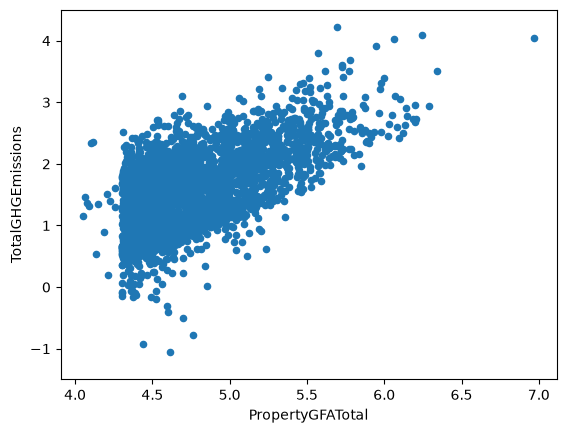

In [18]:
var = 'PropertyGFATotal'
data = pd.concat([totalGHGEmission_log10, np.log10(building_consumption[var])], axis=1)
data.plot.scatter(x=var, y='TotalGHGEmissions', ylim=(-1.5,4.5));

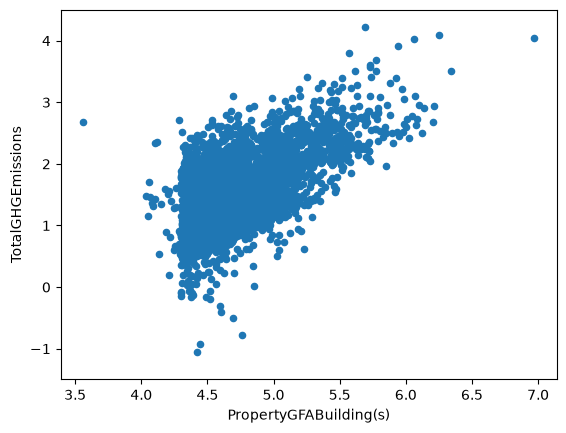

In [19]:
var = 'PropertyGFABuilding(s)'
data = pd.concat([totalGHGEmission_log10, np.log10(building_consumption[var])], axis=1)
data.plot.scatter(x=var, y='TotalGHGEmissions', ylim=(-1.5,4.5));

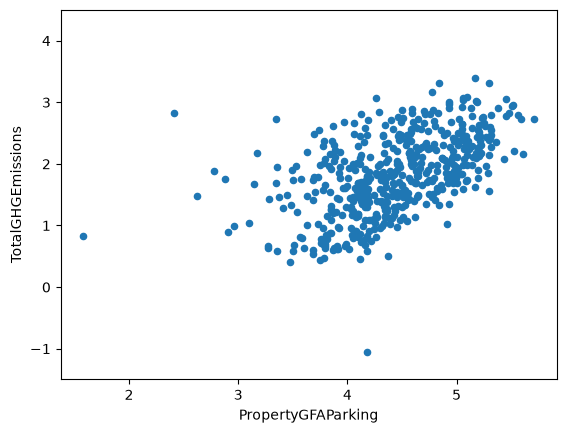

In [20]:
var = 'PropertyGFAParking'
data = pd.concat([totalGHGEmission_log10, np.log10(building_consumption[building_consumption[var] > 0][var])], axis=1)
data.plot.scatter(x=var, y='TotalGHGEmissions', ylim=(-1.5,4.5));

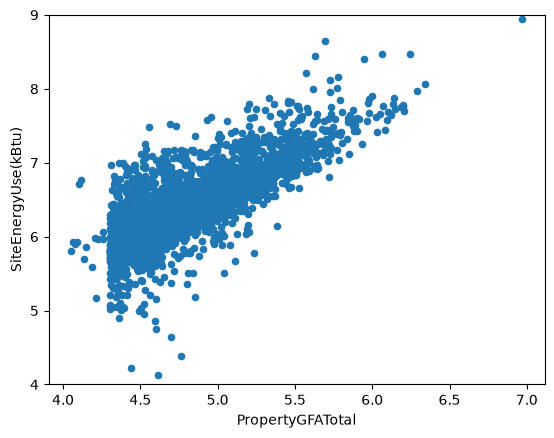

In [21]:
var = 'PropertyGFATotal'
data = pd.concat([siteEnergyUse_log10, np.log10(building_consumption[var])], axis=1)
data.plot.scatter(x=var, y='SiteEnergyUse(kBtu)', ylim=(4,9));

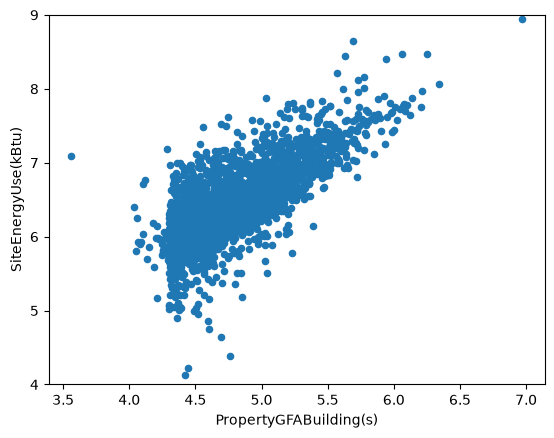

In [22]:
var = 'PropertyGFABuilding(s)'
data = pd.concat([siteEnergyUse_log10, np.log10(building_consumption[var])], axis=1)
data.plot.scatter(x=var, y='SiteEnergyUse(kBtu)', ylim=(4,9));

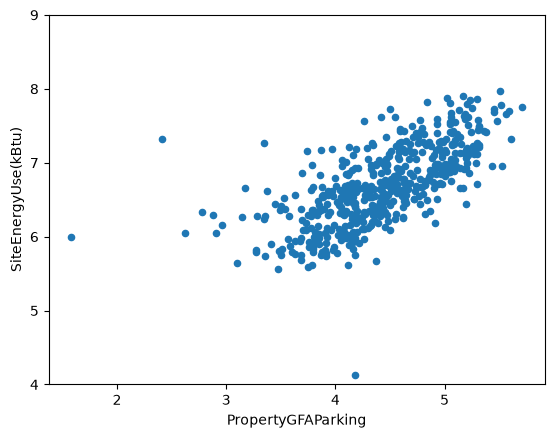

In [23]:
var = 'PropertyGFAParking'
data = pd.concat([siteEnergyUse_log10, np.log10(building_consumption[building_consumption[var] > 0][var])], axis=1)
data.plot.scatter(x=var, y='SiteEnergyUse(kBtu)', ylim=(4,9));

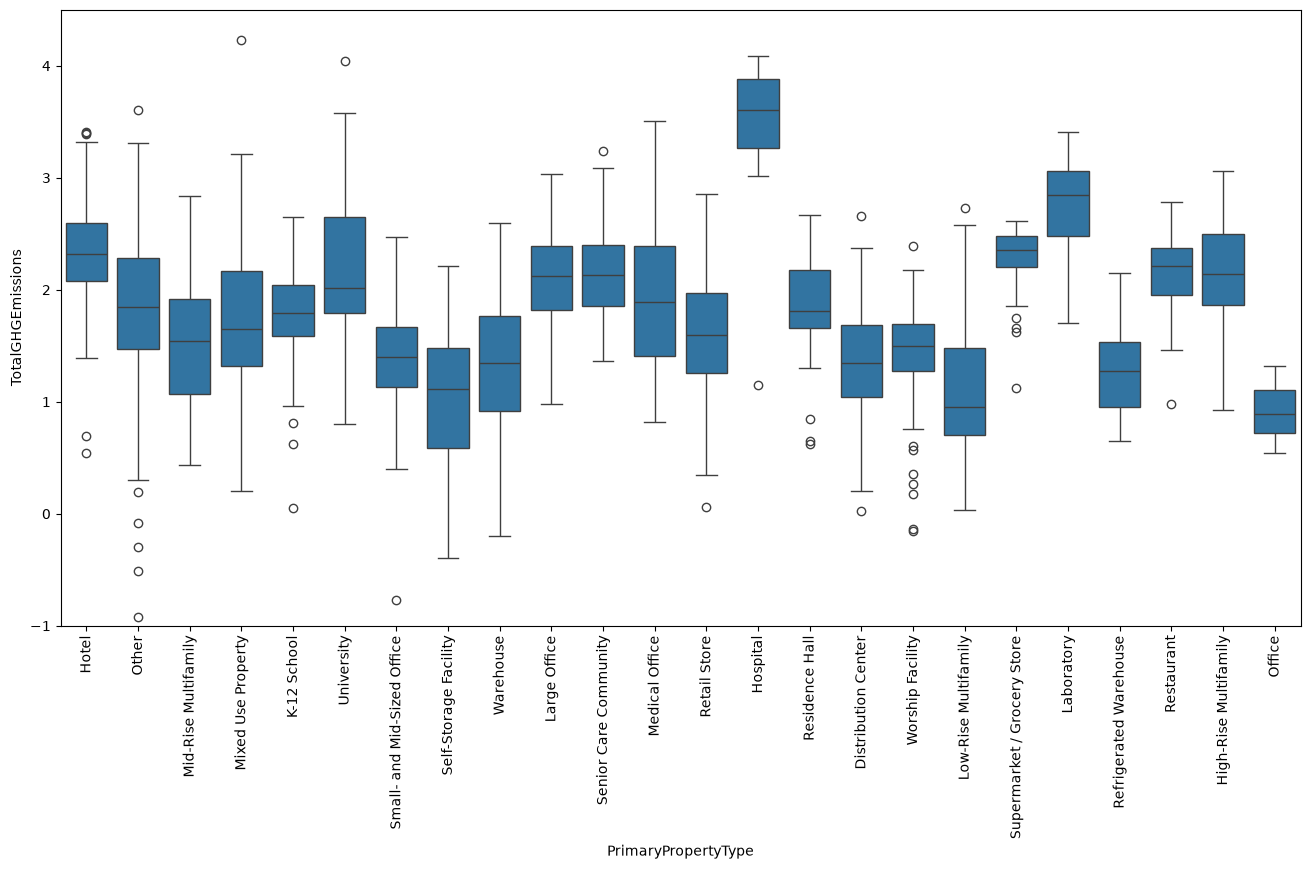

In [24]:
var = 'PrimaryPropertyType'
data = pd.concat([totalGHGEmission_log10, building_consumption[var]], axis=1)
f, ax = plt.subplots(figsize=(16, 8))
fig = sns.boxplot(x=var, y="TotalGHGEmissions", data=data)
fig.axis(ymin=-1, ymax=4.5);
plt.xticks(rotation=90);

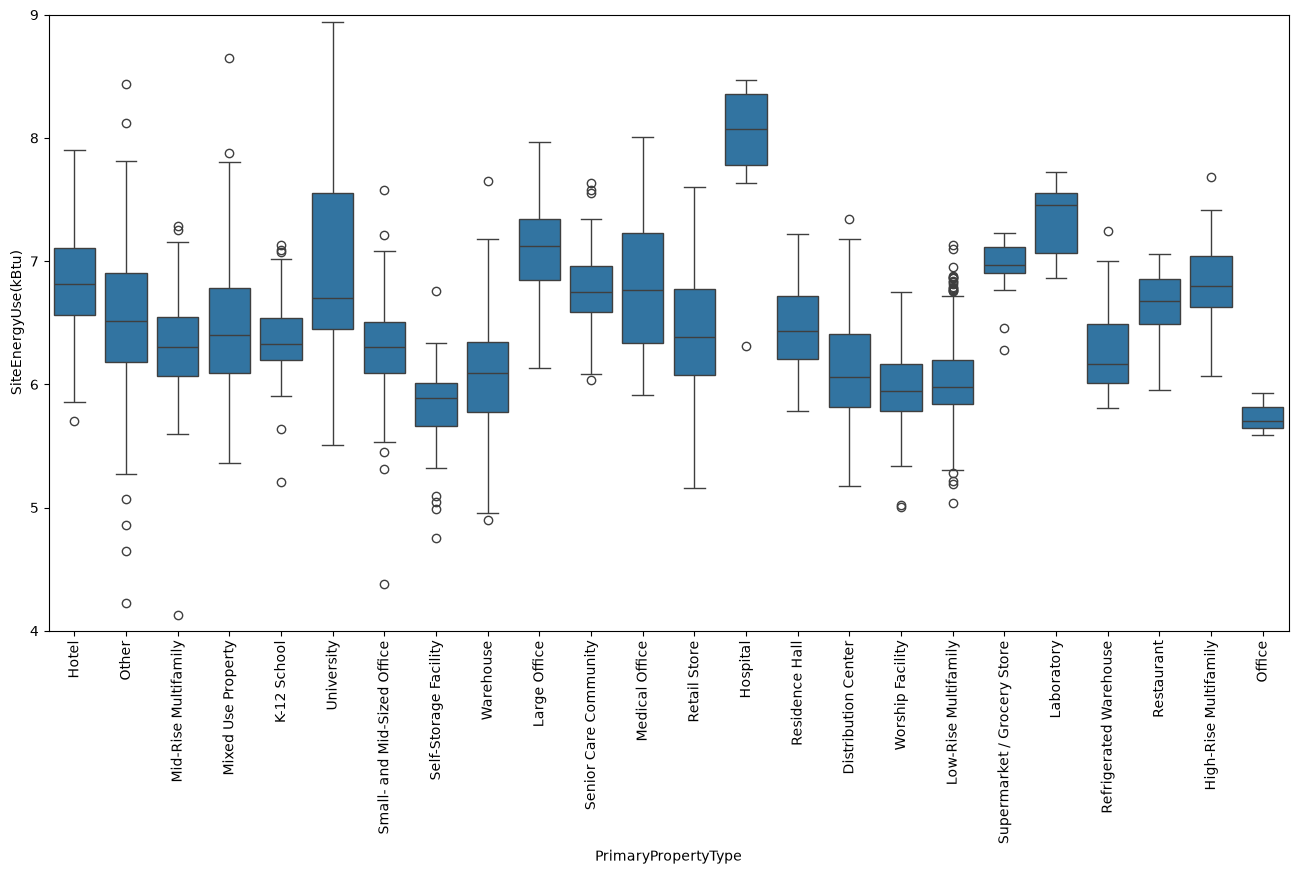

In [25]:
var = 'PrimaryPropertyType'
data = pd.concat([siteEnergyUse_log10, building_consumption[var]], axis=1)
f, ax = plt.subplots(figsize=(16, 8))
fig = sns.boxplot(x=var, y="SiteEnergyUse(kBtu)", data=data)
fig.axis(ymin=4, ymax=9);
plt.xticks(rotation=90);

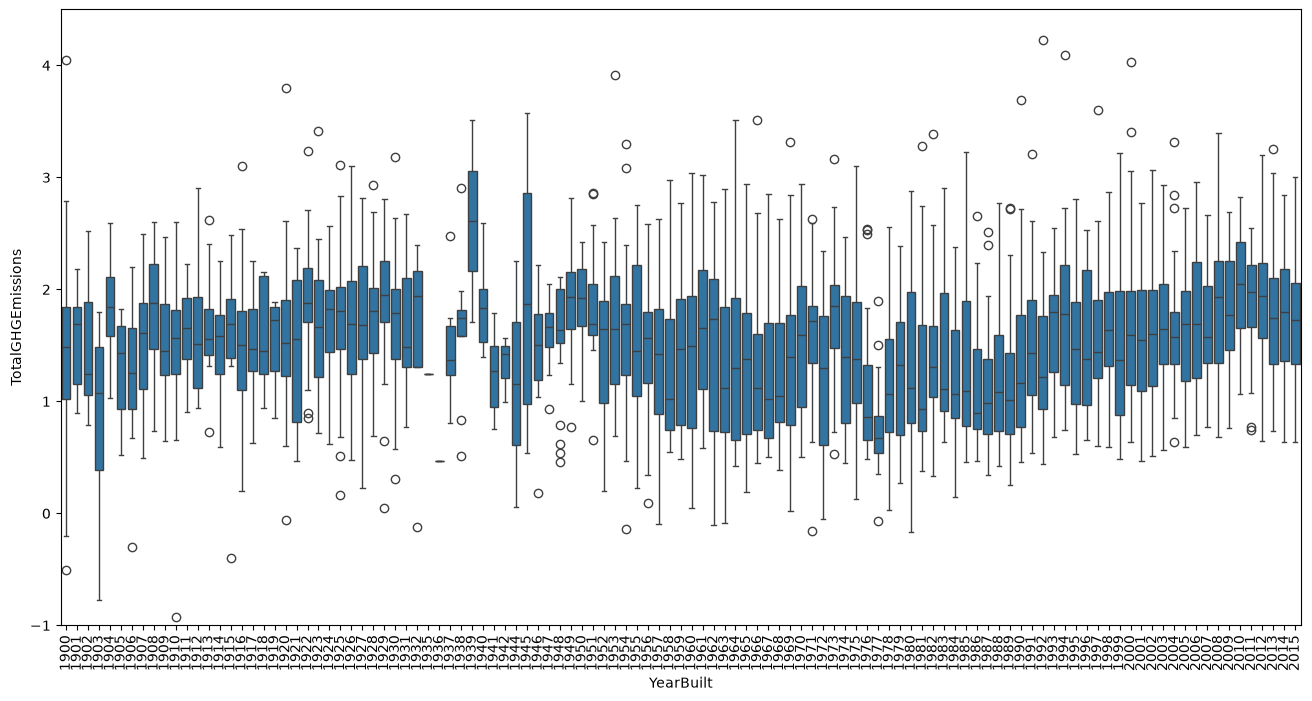

In [26]:
var = 'YearBuilt'
data = pd.concat([totalGHGEmission_log10, building_consumption[var]], axis=1)
f, ax = plt.subplots(figsize=(16, 8))
fig = sns.boxplot(x=var, y="TotalGHGEmissions", data=data)
fig.axis(ymin=-1, ymax=4.5);
plt.xticks(rotation=90);

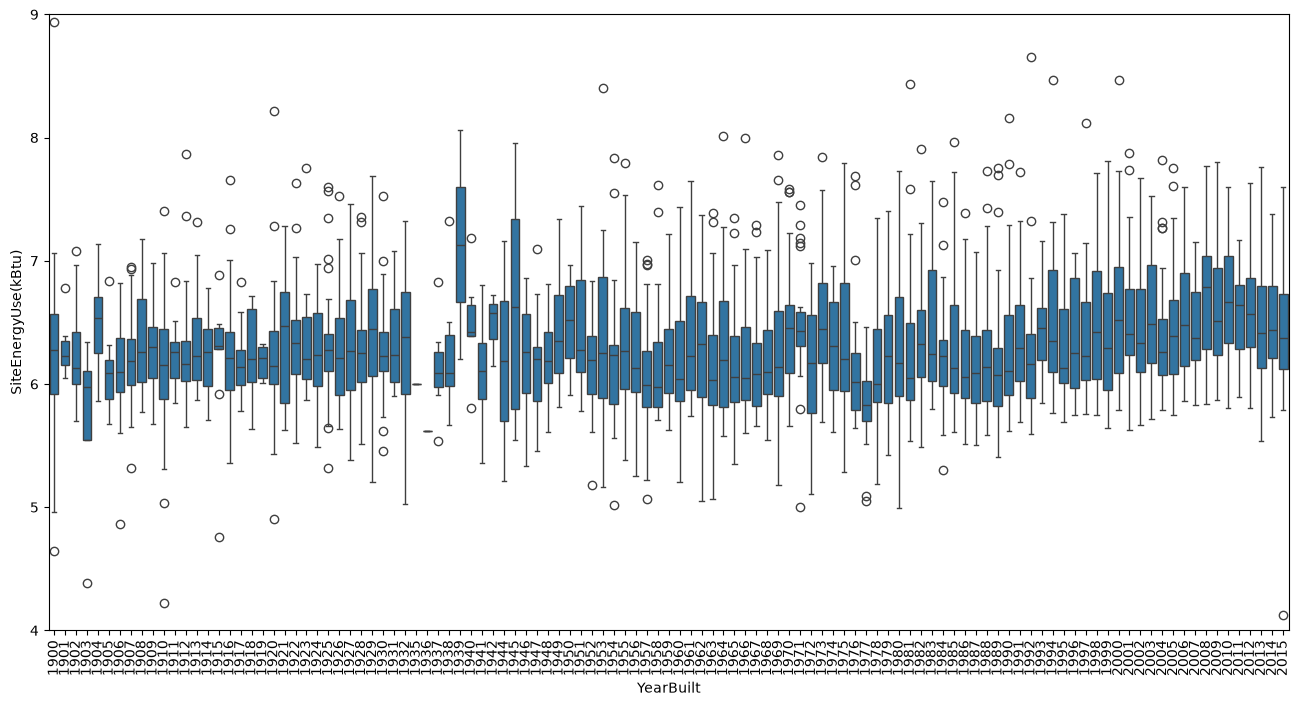

In [27]:
var = 'YearBuilt'
data = pd.concat([siteEnergyUse_log10, building_consumption[var]], axis=1)
f, ax = plt.subplots(figsize=(16, 8))
fig = sns.boxplot(x=var, y="SiteEnergyUse(kBtu)", data=data)
fig.axis(ymin=4, ymax=9);
plt.xticks(rotation=90);

|Variable|Type|Segment|Attente|Conclusion|Commentaire|
|--------|----|-------|-------|----------|-----------|
|OSEBuildingID|identifiant|Identification|basse|à exclure|Identifiant du bâtiment|
|DataYear|numérique|Identification|basse|à exclure|Année de collecte ; constante|
|BuildingType|catégorielle|Usage|moyenne|haute (filtre)|Type générique ; sert surtout à écarter les Multifamily (résidentiel)|
|PrimaryPropertyType|catégorielle|Usage|haute|haute|Usage principal (bureau, hôpital, entrepôt…) : l'intensité énergétique varie fortement selon l'usage|
|PropertyName|texte|Identification|basse|à exclure|Texte libre quasi unique par ligne|
|Address|texte|Localisation|basse|à exclure|Information spatiale|
|City|catégorielle|Localisation|basse|à exclure|Constante (Seattle)|
|State|catégorielle|Localisation|basse|à exclure|Constante (WA)|
|ZipCode|catégorielle|Localisation|basse|basse|Code, pas un nombre ; redondant avec Neighborhood et les coordonnées|
|TaxParcelIdentificationNumber|identifiant|Identification|basse|à exclure|Identifiant cadastral|
|CouncilDistrictCode|catégorielle|Localisation|basse|basse|Code de district (entier) ; redondant avec Neighborhood|
|Neighborhood|catégorielle|Localisation|basse|basse|Effet de quartier surtout indirect (le centre concentre les grands bureaux) ; vérifier les incohérences de casse|
|Latitude|numérique|Localisation|basse|basse|Climat homogène à l'échelle de la ville ; un modèle à arbres peut en tirer un effet de zone|
|Longitude|numérique|Localisation|basse|basse|Idem Latitude|
|YearBuilt|numérique|Bâtiment|moyenne|moyenne|À transformer en âge ; relation non monotone (rénovations, normes successives)|
|NumberofBuildings|numérique|Bâtiment|moyenne|moyenne|Campus multi-bâtiments ; valeurs 0 incohérentes à corriger|
|NumberofFloors|numérique|Bâtiment|moyenne|moyenne|Corrélé à la surface ; valeurs aberrantes à vérifier|
|PropertyGFATotal|numérique|Bâtiment|haute|haute|Surface totale : premier facteur d'échelle de la consommation ; distribution très asymétrique, passage au log conseillé|
|PropertyGFAParking|numérique|Bâtiment|basse|basse|Un parking consomme peu ; la part de parking dans la surface peut être plus utile que la valeur brute|
|PropertyGFABuilding(s)|numérique|Bâtiment|haute|haute|≈ Total − Parking : forte colinéarité avec PropertyGFATotal, n'en garder qu'une pour un modèle linéaire|
|ListOfAllPropertyUseTypes|texte (multi-catégories)|Usage|moyenne|moyenne|Nécessite un encodage multi-hot ; partiellement redondant avec les Largest*|
|LargestPropertyUseType|catégorielle|Usage|haute|haute|Plus fin que PrimaryPropertyType ; arbitrer entre les deux|
|LargestPropertyUseTypeGFA|numérique|Usage|haute|haute|Surface de l'usage principal ; permet de construire des parts de surface par usage|
|SecondLargestPropertyUseType|catégorielle|Usage|moyenne|basse|Beaucoup de manquants, non aléatoires (manquant = pas de second usage)|
|SecondLargestPropertyUseTypeGFA|numérique|Usage|moyenne|moyenne|Manquant à remplacer par 0 ; utile surtout en proportion de la surface totale|
|ThirdLargestPropertyUseType|catégorielle|Usage|basse|basse|Très lacunaire|
|ThirdLargestPropertyUseTypeGFA|numérique|Usage|basse|basse|Très lacunaire ; même traitement que le second usage|
|YearsENERGYSTARCertified|texte|Énergie|basse|à exclure|Très lacunaire ; la certification dépend elle-même des consommations mesurées|
|ENERGYSTARScore|numérique|Énergie|haute|à évaluer à part|Calculé à partir des consommations réelles (fuite partielle) et nombreux manquants ; tester le modèle avec et sans|
|SiteEUI(kBtu/sf)|numérique|Énergie|très haute|à exclure (fuite)|= SiteEnergyUse / surface : c'est la cible divisée par la surface ; peut servir de cible alternative (intensité)|
|SiteEUIWN(kBtu/sf)|numérique|Énergie|très haute|à exclure (fuite)|Version normalisée météo de SiteEUI|
|SourceEUI(kBtu/sf)|numérique|Énergie|très haute|à exclure (fuite)|Intensité en énergie primaire, dérivée des relevés|
|SourceEUIWN(kBtu/sf)|numérique|Énergie|très haute|à exclure (fuite)|Idem, normalisée météo|
|SiteEnergyUse(kBtu)|numérique|Cible|—|cible|Cible 1 ; très asymétrique, modéliser le log|
|SiteEnergyUseWN(kBtu)|numérique|Énergie|très haute|à exclure (fuite)|Version normalisée météo de la cible|
|SteamUse(kBtu)|numérique|Énergie|très haute|à exclure (fuite)|Composante de la cible (somme vapeur + électricité + gaz)|
|Electricity(kWh)|numérique|Énergie|très haute|à exclure (fuite)|Composante de la cible ; doublon exact d'Electricity(kBtu) à un facteur près|
|Electricity(kBtu)|numérique|Énergie|très haute|à exclure (fuite)|Composante de la cible|
|NaturalGas(therms)|numérique|Énergie|très haute|à exclure (fuite)|Composante de la cible ; doublon de NaturalGas(kBtu)|
|NaturalGas(kBtu)|numérique|Énergie|très haute|à exclure (fuite)|Composante de la cible ; principal moteur des émissions|
|DefaultData|booléen|Qualité|basse|basse (filtre)|Signale des valeurs par défaut : indicateur de qualité, candidat au filtrage des lignes|
|Comments|texte|Qualité|basse|à exclure|Quasi vide|
|ComplianceStatus|catégorielle|Qualité|basse|filtre|Garder les lignes conformes : les non conformes ont souvent des données douteuses|
|Outlier|catégorielle|Qualité|basse|filtre|Aberrations signalées par la ville ; sert à exclure des lignes, pas comme feature|
|TotalGHGEmissions|numérique|Cible|—|cible|Cible 2 ; très asymétrique, modéliser le log|
|GHGEmissionsIntensity|numérique|Énergie|très haute|à exclure (fuite)|= TotalGHGEmissions / surface|

# Modélisation 

### Import des modules 

In [28]:
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_validate,
    KFold
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor


### Feature Engineering

A réaliser : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

En règle générale : On utilise la méthode .apply() de Pandas pour créer une nouvelle colonne à partir d'une colonne existante. N'hésitez pas à regarder les exemples dans les chapitres de cours donnés en ressource

In [29]:
building_consumption.columns

Index(['OSEBuildingID', 'DataYear', 'BuildingType', 'PrimaryPropertyType',
       'PropertyName', 'Address', 'City', 'State', 'ZipCode',
       'TaxParcelIdentificationNumber', 'CouncilDistrictCode', 'Neighborhood',
       'Latitude', 'Longitude', 'YearBuilt', 'NumberofBuildings',
       'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking',
       'PropertyGFABuilding(s)', 'ListOfAllPropertyUseTypes',
       'LargestPropertyUseType', 'LargestPropertyUseTypeGFA',
       'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA',
       'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA',
       'YearsENERGYSTARCertified', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)',
       'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)',
       'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)',
       'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)',
       'NaturalGas(kBtu)', 'DefaultData', 'Comments', 'ComplianceStatus',
       'Outlier

In [30]:
building_consumption_columns_keep = building_consumption[[
    'BuildingType',
    'PrimaryPropertyType',
    'Latitude',
    'Longitude',
    'YearBuilt',
    'NumberofBuildings',
    'NumberofFloors',
    'PropertyGFATotal',
    'PropertyGFAParking',
    'PropertyGFABuilding(s)',
    'ListOfAllPropertyUseTypes',
    'LargestPropertyUseType',
    'LargestPropertyUseTypeGFA',
    'SecondLargestPropertyUseType',
    'SecondLargestPropertyUseTypeGFA',
    'ThirdLargestPropertyUseType',
    'ThirdLargestPropertyUseTypeGFA',
    'DefaultData',
    'ComplianceStatus',
    'Outlier',
    'SteamUse(kBtu)',
    'Electricity(kBtu)',
    'NaturalGas(kBtu)',
    'SiteEnergyUse(kBtu)',
    'TotalGHGEmissions'
]]

In [31]:
print(building_consumption_columns_keep.shape[0])
building_consumption_non_residential = building_consumption_columns_keep[~building_consumption_columns_keep['BuildingType'].str.contains('Multifamily')]
print(building_consumption_non_residential.shape[0])
building_consumption_target_missing = building_consumption_non_residential[(building_consumption_non_residential['SiteEnergyUse(kBtu)'] > 0) & (building_consumption_non_residential['TotalGHGEmissions'] > 0)]
print(building_consumption_target_missing.shape[0])


3376
1668
1648


In [32]:
building_consumption_target_missing.columns
for column in building_consumption_target_missing.columns:
    column_shape = None
    if building_consumption_target_missing[column].dtype == 'str':
        column_shape = building_consumption_target_missing[building_consumption_target_missing[column] == None].shape
    else:
        column_shape = building_consumption_target_missing[building_consumption_target_missing[column] == 0].shape
    if column_shape[0] > 0:
        print(column, ':', column_shape)

NumberofBuildings : (52, 25)
NumberofFloors : (16, 25)
PropertyGFAParking : (1315, 25)
SecondLargestPropertyUseTypeGFA : (80, 25)
ThirdLargestPropertyUseTypeGFA : (24, 25)
DefaultData : (1561, 25)
SteamUse(kBtu) : (1534, 25)
Electricity(kBtu) : (1, 25)
NaturalGas(kBtu) : (463, 25)


In [33]:
print(building_consumption_target_missing[building_consumption_target_missing['NumberofBuildings'] == 0].shape)
building_consumption_target_missing[building_consumption_target_missing['NumberofBuildings'] == 0][['ListOfAllPropertyUseTypes']]

(52, 25)


,ListOfAllPropertyUseTypes
63,Medical Office
76,"Data Center, Distribution Center, Office, Park..."
160,Non-Refrigerated Warehouse
201,Office
241,Office
264,"Distribution Center, Non-Refrigerated Warehous..."
278,"Office, Other, Retail Store"
280,Hotel
291,"Movie Theater, Other - Restaurant/Bar, Parking"
358,"Office, Other - Services"


In [34]:
building_consumption_target_missing[building_consumption_target_missing['NumberofBuildings'] > 4][['NumberofBuildings','ListOfAllPropertyUseTypes']]

,NumberofBuildings,ListOfAllPropertyUseTypes
105,27.0,College/University
124,6.0,Hospital (General Medical & Surgical)
128,11.0,College/University
162,14.0,"Laboratory, Non-Refrigerated Warehouse, Office..."
167,6.0,"Hospital (General Medical & Surgical), Parking"
170,9.0,"Hospital (General Medical & Surgical), Parking"
364,6.0,"Parking, Strip Mall"
448,5.0,Office
618,7.0,"Hospital (General Medical & Surgical), Parking"
954,5.0,K-12 School


In [35]:
building_consumption_numberofbuildings_missing = building_consumption_target_missing[building_consumption_target_missing['NumberofBuildings'] > 0]
print(building_consumption_numberofbuildings_missing.shape[0])
building_consumption_clean = building_consumption_numberofbuildings_missing[building_consumption_numberofbuildings_missing['NumberofFloors'] > 0]
print(building_consumption_clean.shape[0])

1596
1581


In [36]:
building_consumption_clean[['ComplianceStatus']].value_counts()

ComplianceStatus            
Compliant                       1479
Error - Correct Default Data      87
Non-Compliant                     15
Name: count, dtype: int64

In [37]:
building_consumption_outlier = building_consumption_clean[~building_consumption_clean['Outlier'].str.contains('outlier')]
print(building_consumption_outlier.shape[0])
building_consumption_compliance = building_consumption_outlier[
    (building_consumption_outlier['ComplianceStatus'] == 'Compliant') |
    ((building_consumption_outlier['ComplianceStatus'] == 'Error - Correct Default Data') & (building_consumption_outlier['DefaultData'] == True))
]
print(building_consumption_compliance.shape[0])
building_consumption_final = building_consumption_compliance

1564
1564


In [38]:
building_consumption_final[['SiteEnergyUse(kBtu)']].describe()

,SiteEnergyUse(kBtu)
count,1.564000e+03
mean,7.900286e+06
std,2.195635e+07
min,5.713320e+04
25%,1.256212e+06
50%,2.563995e+06
75%,6.858700e+06
max,4.483853e+08


In [39]:
building_consumption_final[['TotalGHGEmissions']].describe()

,TotalGHGEmissions
count,1564.000000
mean,178.137046
std,720.191253
min,0.400000
25%,20.655000
50%,49.565000
75%,138.475000
max,16870.980000


In [40]:
building_consumption_final[['PrimaryPropertyType']].value_counts()

PrimaryPropertyType        
Small- and Mid-Sized Office    276
Other                          228
Warehouse                      183
Large Office                   166
K-12 School                    123
Mixed Use Property             107
Retail Store                    86
Hotel                           72
Worship Facility                68
Distribution Center             53
Supermarket / Grocery Store     37
Medical Office                  34
Self-Storage Facility           28
University                      23
Senior Care Community           20
Residence Hall                  16
Refrigerated Warehouse          11
Restaurant                      11
Hospital                         9
Laboratory                       8
Office                           3
Low-Rise Multifamily             2
Name: count, dtype: int64

In [41]:
print(building_consumption_final[building_consumption_final['PrimaryPropertyType'] == 'Low-Rise Multifamily'][
    ['BuildingType', 'PrimaryPropertyType', 'LargestPropertyUseType', 'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType', 'ListOfAllPropertyUseTypes']
])

        BuildingType   PrimaryPropertyType LargestPropertyUseType  \
644   NonResidential  Low-Rise Multifamily    Multifamily Housing   
1300          Campus  Low-Rise Multifamily    Multifamily Housing   

     SecondLargestPropertyUseType ThirdLargestPropertyUseType  \
644                           NaN                         NaN   
1300                 Retail Store                  Restaurant   

                              ListOfAllPropertyUseTypes  
644                                 Multifamily Housing  
1300  Bar/Nightclub, Food Sales, Multifamily Housing...  


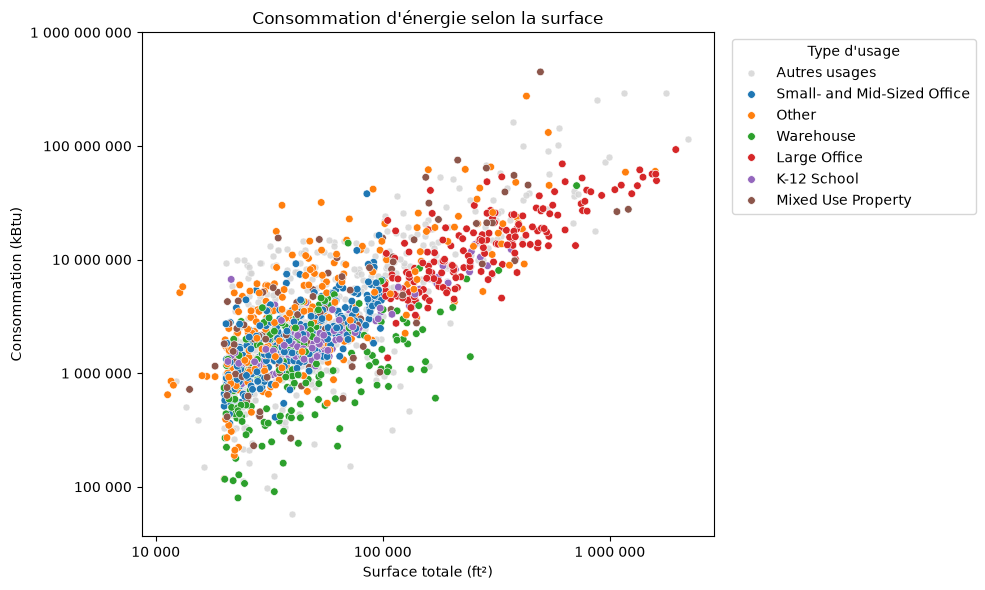

In [42]:
building_consumption_final['SiteEnergyUse(kBtu)_log10'] = np.log10(building_consumption_final['SiteEnergyUse(kBtu)'])
building_consumption_final['TotalGHGEmissions_log10'] = np.log10(building_consumption_final['TotalGHGEmissions'])
building_consumption_final['PropertyGFATotal_log10'] = np.log10(building_consumption_final['PropertyGFATotal'])

hue_order = ['Small- and Mid-Sized Office', 'Other', 'Warehouse', 'Large Office', 'K-12 School', 'Mixed Use Property']

building_consumption_principaux = building_consumption_final[building_consumption_final['PrimaryPropertyType'].isin(hue_order)]
building_consumption_autres = building_consumption_final[~building_consumption_final['PrimaryPropertyType'].isin(hue_order)]

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=building_consumption_autres, x='PropertyGFATotal_log10', y='SiteEnergyUse(kBtu)_log10', color='lightgray',
                alpha=0.8, s=25, label='Autres usages', ax=ax)

sns.scatterplot(building_consumption_principaux, x='PropertyGFATotal_log10', y='SiteEnergyUse(kBtu)_log10', hue='PrimaryPropertyType',
                hue_order=hue_order, s=30, ax=ax)

ax.set_xlabel("Surface totale (ft²)")
ax.set_ylabel("Consommation (kBtu)")
ax.set_title("Consommation d'énergie selon la surface")
ax.legend(title="Type d'usage", bbox_to_anchor=(1.02, 1), loc='upper left')

ax.set_xticks([4, 5, 6])
ax.set_xticklabels(['10 000', '100 000', '1 000 000'])
ax.set_yticks([5, 6, 7, 8, 9])
ax.set_yticklabels(['100 000', '1 000 000', '10 000 000', '100 000 000', '1 000 000 000'])

plt.tight_layout()

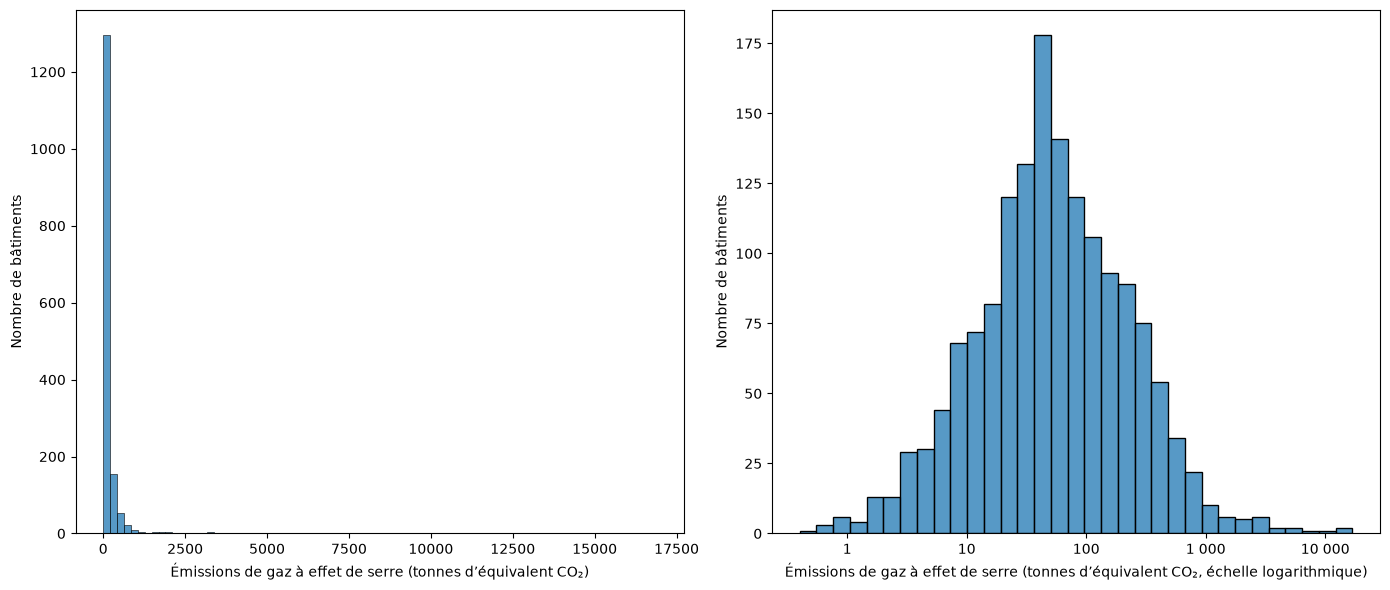

In [43]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 6))
sns.histplot(building_consumption_final, x='TotalGHGEmissions', ax=ax1)
sns.histplot(building_consumption_final, x='TotalGHGEmissions_log10', ax=ax2)

ax1.set_xlabel("Émissions de gaz à effet de serre (tonnes d’équivalent CO₂)")
ax1.set_ylabel("Nombre de bâtiments")

ax2.set_xlabel("Émissions de gaz à effet de serre (tonnes d’équivalent CO₂, échelle logarithmique)")
ax2.set_ylabel("Nombre de bâtiments")
ax2.set_xticks([0, 1, 2, 3, 4])
ax2.set_xticklabels(['1', '10', '100', '1 000', '10 000'])

plt.tight_layout()
plt.show()

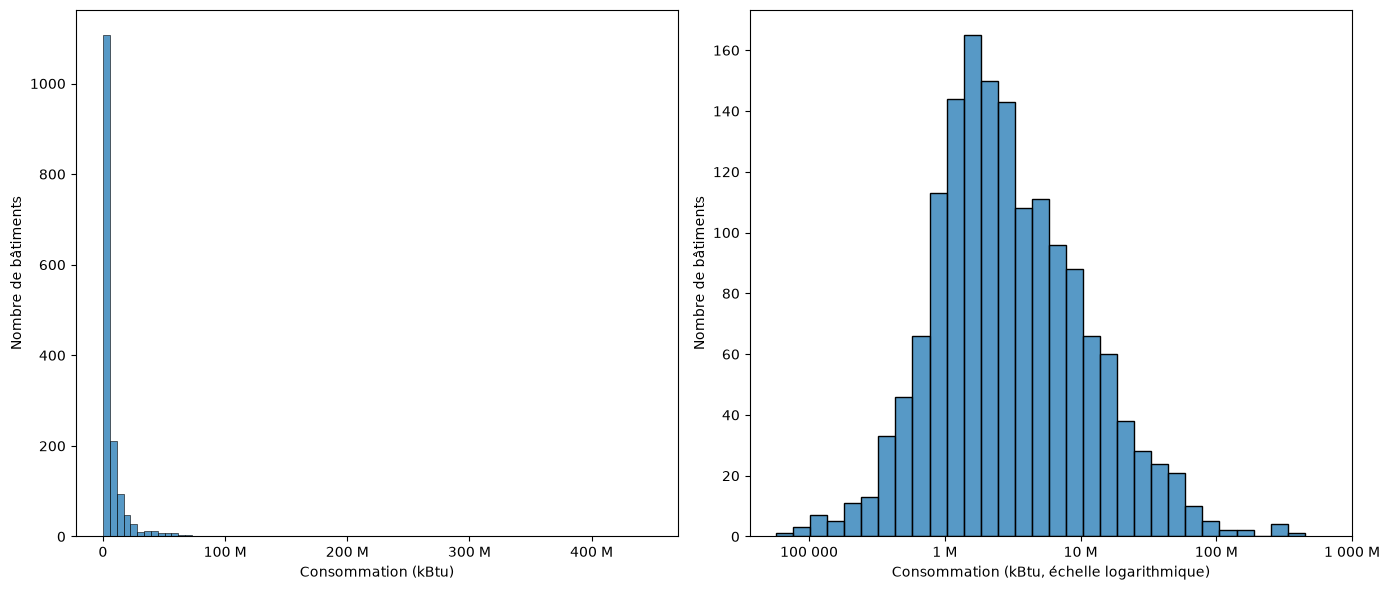

In [44]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 6))
sns.histplot(building_consumption_final, x='SiteEnergyUse(kBtu)', ax=ax1)
sns.histplot(building_consumption_final, x='SiteEnergyUse(kBtu)_log10', ax=ax2)

ax1.set_xlabel("Consommation (kBtu)")
ax1.set_ylabel("Nombre de bâtiments")
ax1.set_xticks([0, 100000000, 200000000, 300000000, 400000000])
ax1.set_xticklabels(['0', '100 M', '200 M', '300 M', '400 M'])

ax2.set_xlabel("Consommation (kBtu, échelle logarithmique)")
ax2.set_ylabel("Nombre de bâtiments")
ax2.set_xticks([5, 6, 7, 8, 9])
ax2.set_xticklabels(['100 000', '1 M', '10 M', '100 M', '1 000 M'])

plt.tight_layout()
plt.show()

In [45]:
mean_energy_by_type = building_consumption_final.groupby('PrimaryPropertyType')['SiteEnergyUse(kBtu)_log10'].mean()
mean_energy_by_type.sort_values(ascending=False, inplace=True)
mean_energy_by_type.index
mean_energy_by_type

PrimaryPropertyType
Hospital                       8.103157
Laboratory                     7.272440
Large Office                   7.106635
Supermarket / Grocery Store    6.969112
Senior Care Community          6.889822
Hotel                          6.824243
University                     6.805027
Medical Office                 6.765369
Restaurant                     6.603397
Other                          6.568898
Mixed Use Property             6.493343
Low-Rise Multifamily           6.438860
Retail Store                   6.421983
K-12 School                    6.393448
Refrigerated Warehouse         6.336665
Residence Hall                 6.328247
Small- and Mid-Sized Office    6.307529
Distribution Center            6.106515
Warehouse                      6.054152
Worship Facility               5.979056
Self-Storage Facility          5.786658
Office                         5.739730
Name: SiteEnergyUse(kBtu)_log10, dtype: float64

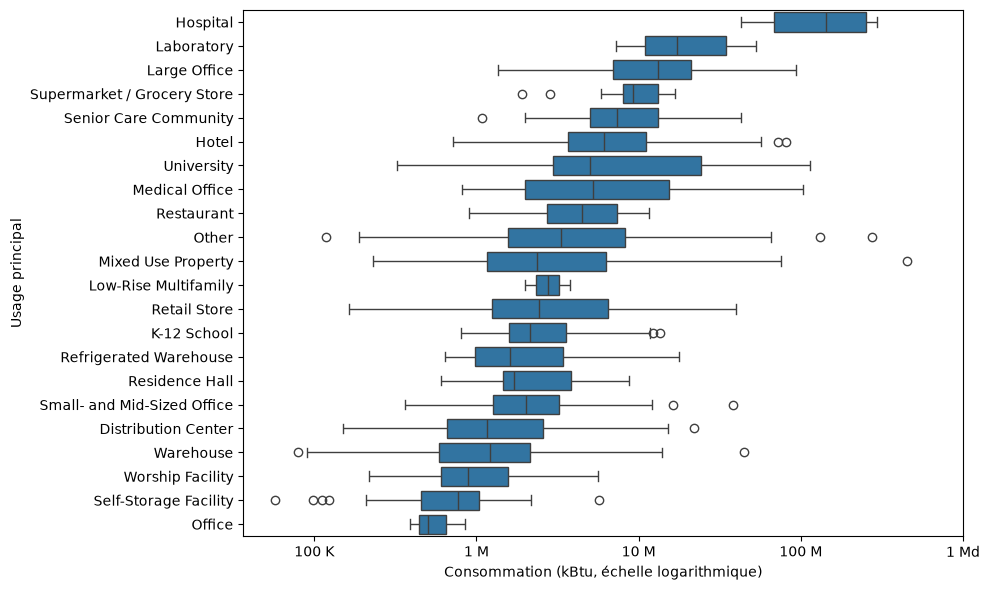

In [46]:


fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(building_consumption_final, x='SiteEnergyUse(kBtu)_log10', y='PrimaryPropertyType', order=mean_energy_by_type.index, ax=ax)

ax.set_xlabel('Consommation (kBtu, échelle logarithmique)')
ax.set_ylabel('Usage principal')

ax.set_xticks([5, 6, 7, 8, 9])
ax.set_xticklabels(['100 K', '1 M', '10 M', '100 M', '1 Md'])

plt.tight_layout()
plt.show()

In [47]:
building_consumption_final['DecadeBuilt'] = (building_consumption_final['YearBuilt'] // 10) * 10
building_consumption_final

,BuildingType,PrimaryPropertyType,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),...,Outlier,SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),SiteEnergyUse(kBtu),TotalGHGEmissions,SiteEnergyUse(kBtu)_log10,TotalGHGEmissions_log10,PropertyGFATotal_log10,DecadeBuilt
0,NonResidential,Hotel,47.61220,-122.33799,1927,1.0,12,88434,0,88434,...,NaN,2003882.00,3.946027e+06,1.276453e+06,7.226362e+06,249.98,6.858920,2.397905,4.946619,1920
1,NonResidential,Hotel,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,...,NaN,0.00,3.242851e+06,5.145082e+06,8.387933e+06,295.86,6.923655,2.471086,5.015217,1990
2,NonResidential,Hotel,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,...,NaN,21566554.00,4.952666e+07,1.493800e+06,7.258702e+07,2089.28,7.860859,3.319997,5.980508,1960
3,NonResidential,Hotel,47.61412,-122.33664,1926,1.0,10,61320,0,61320,...,NaN,2214446.25,2.768924e+06,1.811213e+06,6.794584e+06,286.43,6.832163,2.457019,4.787602,1920
4,NonResidential,Hotel,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,...,NaN,0.00,5.368607e+06,8.803998e+06,1.417261e+07,505.01,7.151450,2.703300,5.244475,1980
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3371,Nonresidential COS,Office,47.56722,-122.31154,1990,1.0,1,12294,0,12294,...,NaN,0.00,5.242709e+05,3.254750e+05,8.497457e+05,20.94,5.929289,1.320977,4.089693,1990
3372,Nonresidential COS,Other,47.59625,-122.32283,2004,1.0,1,16000,0,16000,...,NaN,0.00,3.965461e+05,5.537300e+05,9.502762e+05,32.17,5.977850,1.507451,4.204120,2000
3373,Nonresidential COS,Other,47.63644,-122.35784,1974,1.0,1,13157,0,13157,...,NaN,0.00,1.792159e+06,3.973739e+06,5.765898e+06,223.54,6.760867,2.349355,4.119157,1970
3374,Nonresidential COS,Mixed Use Property,47.52832,-122.32431,1989,1.0,1,14101,0,14101,...,NaN,0.00,3.488702e+05,3.706010e+05,7.194712e+05,22.11,5.857013,1.344589,4.149250,1980


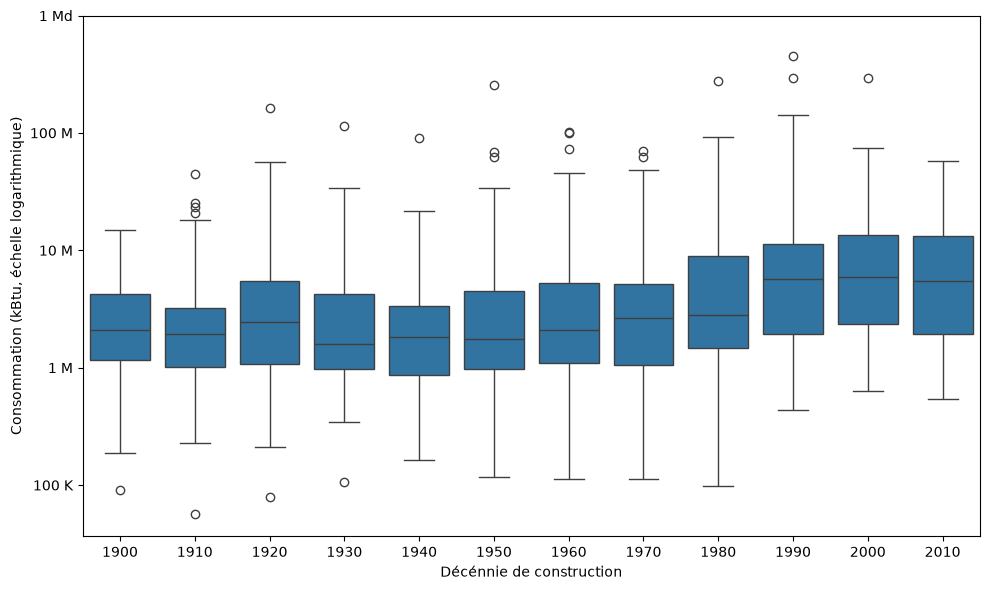

In [48]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(building_consumption_final, x='DecadeBuilt', y='SiteEnergyUse(kBtu)_log10', ax=ax)

ax.set_xlabel('Décénnie de construction')
ax.set_ylabel('Consommation (kBtu, échelle logarithmique)')

ax.set_yticks([5, 6, 7, 8, 9])
ax.set_yticklabels(['100 K', '1 M', '10 M', '100 M', '1 Md'])

plt.tight_layout()
plt.show()

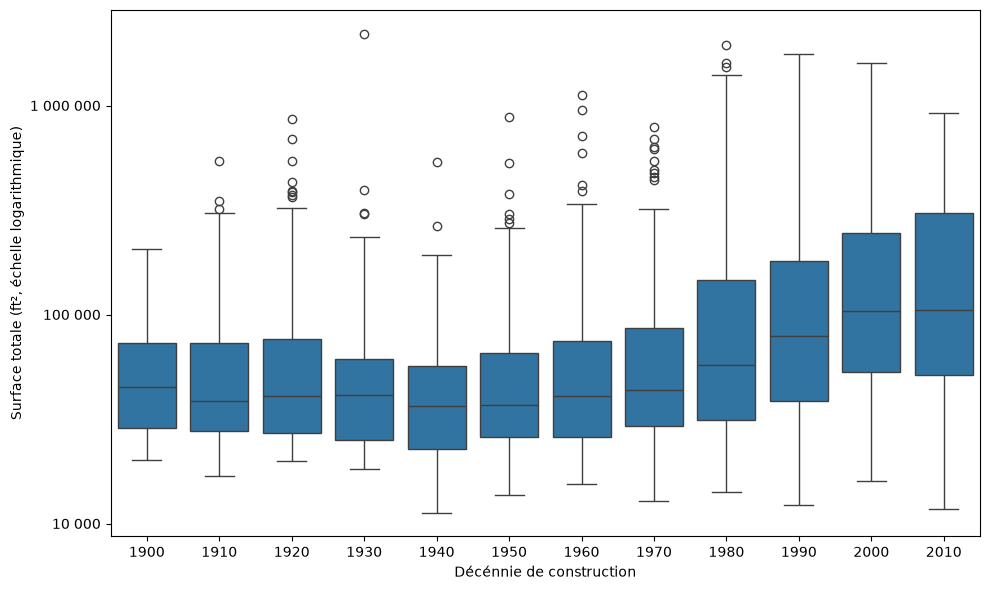

In [49]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(building_consumption_final, x='DecadeBuilt', y='PropertyGFATotal_log10', ax=ax)

ax.set_xlabel('Décénnie de construction')
ax.set_ylabel('Surface totale (ft², échelle logarithmique)')

ax.set_yticks([4, 5, 6])
ax.set_yticklabels(['10 000', '100 000', '1 000 000'])

plt.tight_layout()
plt.show()

### Préparation des features pour la modélisation

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de features) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

In [50]:
from category_encoders.binary import BinaryEncoder

encoder = BinaryEncoder()
building_consumption_bin = encoder.fit_transform(building_consumption_final[['PrimaryPropertyType', 'LargestPropertyUseType', 'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType']])
print(building_consumption_bin.shape)
print(building_consumption_bin)
print(building_consumption_final[['PrimaryPropertyType', 'LargestPropertyUseType', 'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType']])
building_consumption_encoded = pd.concat([building_consumption_final, building_consumption_bin], axis=1)


(1564, 23)
      PrimaryPropertyType_0  PrimaryPropertyType_1  PrimaryPropertyType_2  \
0                         0                      0                      0   
1                         0                      0                      0   
2                         0                      0                      0   
3                         0                      0                      0   
4                         0                      0                      0   
...                     ...                    ...                    ...   
3371                      1                      0                      1   
3372                      0                      0                      0   
3373                      0                      0                      0   
3374                      0                      0                      0   
3375                      0                      0                      0   

      PrimaryPropertyType_3  PrimaryPropertyType_4  LargestPrope

In [51]:
# CODE PREPARATION DES FEATURES
building_consumption_encoded['BuildingAge'] = datetime.datetime.now().year - building_consumption_encoded['YearBuilt']
building_consumption_encoded['NumberofUseTypes'] = building_consumption_encoded['ListOfAllPropertyUseTypes'].str.split(',').apply(len)
building_consumption_encoded['GFAbyFloor'] = building_consumption_encoded['PropertyGFATotal'] / building_consumption_encoded['NumberofFloors']
print(building_consumption_encoded.columns)
building_consumption_encoded[['BuildingAge', 'NumberofUseTypes', 'GFAbyFloor']]

Index(['BuildingType', 'PrimaryPropertyType', 'Latitude', 'Longitude',
       'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal',
       'PropertyGFAParking', 'PropertyGFABuilding(s)',
       'ListOfAllPropertyUseTypes', 'LargestPropertyUseType',
       'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType',
       'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType',
       'ThirdLargestPropertyUseTypeGFA', 'DefaultData', 'ComplianceStatus',
       'Outlier', 'SteamUse(kBtu)', 'Electricity(kBtu)', 'NaturalGas(kBtu)',
       'SiteEnergyUse(kBtu)', 'TotalGHGEmissions', 'SiteEnergyUse(kBtu)_log10',
       'TotalGHGEmissions_log10', 'PropertyGFATotal_log10', 'DecadeBuilt',
       'PrimaryPropertyType_0', 'PrimaryPropertyType_1',
       'PrimaryPropertyType_2', 'PrimaryPropertyType_3',
       'PrimaryPropertyType_4', 'LargestPropertyUseType_0',
       'LargestPropertyUseType_1', 'LargestPropertyUseType_2',
       'LargestPropertyUseType_3', 'LargestProp

,BuildingAge,NumberofUseTypes,GFAbyFloor
0,99,1,7369.500000
1,30,3,9415.090909
2,57,1,23319.756098
3,100,1,6132.000000
4,46,3,9754.444444
...,...,...,...
3371,36,1,12294.000000
3372,22,1,16000.000000
3373,52,3,13157.000000
3374,37,5,14101.000000


In [52]:
building_consumption_encoded.columns
print(building_consumption_encoded[['SecondLargestPropertyUseType', 'SecondLargestPropertyUseType_0', 'SecondLargestPropertyUseType_1', 'SecondLargestPropertyUseType_2', 'SecondLargestPropertyUseType_3', 'SecondLargestPropertyUseType_4', 'SecondLargestPropertyUseType_5']])

        SecondLargestPropertyUseType  SecondLargestPropertyUseType_0  \
0                                NaN                               1   
1                            Parking                               0   
2                                NaN                               1   
3                                NaN                               1   
4                            Parking                               0   
...                              ...                             ...   
3371                             NaN                               1   
3372                             NaN                               1   
3373  Fitness Center/Health Club/Gym                               1   
3374  Fitness Center/Health Club/Gym                               1   
3375  Fitness Center/Health Club/Gym                               1   

      SecondLargestPropertyUseType_1  SecondLargestPropertyUseType_2  \
0                                  1                           

### Comparaison de différents modèles supervisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

In [53]:
building_consumption_encoded.columns

Index(['BuildingType', 'PrimaryPropertyType', 'Latitude', 'Longitude',
       'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal',
       'PropertyGFAParking', 'PropertyGFABuilding(s)',
       'ListOfAllPropertyUseTypes', 'LargestPropertyUseType',
       'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType',
       'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType',
       'ThirdLargestPropertyUseTypeGFA', 'DefaultData', 'ComplianceStatus',
       'Outlier', 'SteamUse(kBtu)', 'Electricity(kBtu)', 'NaturalGas(kBtu)',
       'SiteEnergyUse(kBtu)', 'TotalGHGEmissions', 'SiteEnergyUse(kBtu)_log10',
       'TotalGHGEmissions_log10', 'PropertyGFATotal_log10', 'DecadeBuilt',
       'PrimaryPropertyType_0', 'PrimaryPropertyType_1',
       'PrimaryPropertyType_2', 'PrimaryPropertyType_3',
       'PrimaryPropertyType_4', 'LargestPropertyUseType_0',
       'LargestPropertyUseType_1', 'LargestPropertyUseType_2',
       'LargestPropertyUseType_3', 'LargestProp

In [54]:
X = building_consumption_encoded[[
    'BuildingAge', 'NumberofBuildings', 'NumberofFloors', 'NumberofUseTypes', 'PropertyGFATotal', 'LargestPropertyUseType_0', 'LargestPropertyUseType_1',
    'LargestPropertyUseType_2', 'LargestPropertyUseType_3', 'LargestPropertyUseType_4', 'LargestPropertyUseType_5',
    'SecondLargestPropertyUseType_0', 'SecondLargestPropertyUseType_1', 'SecondLargestPropertyUseType_2', 'SecondLargestPropertyUseType_3',
    'SecondLargestPropertyUseType_4', 'SecondLargestPropertyUseType_5', 'ThirdLargestPropertyUseType_0', 'ThirdLargestPropertyUseType_1',
    'ThirdLargestPropertyUseType_2', 'ThirdLargestPropertyUseType_3', 'ThirdLargestPropertyUseType_4', 'ThirdLargestPropertyUseType_5',
    'GFAbyFloor'
]]

y = building_consumption_encoded[['SiteEnergyUse(kBtu)_log10', 'TotalGHGEmissions_log10']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=213)

In [55]:
def perform_cross_validation(
    X: pd.DataFrame,
    y: pd.DataFrame,
    model,
    cross_val_type, # La variante de validation croisée que nous souhaitons utiliser
    scoring_metrics: tuple, # Metriques de notre choix
    return_estimator=False, # Si nous souhaitons stocker les modèles de chaque fold
    groups=None, # Nous verrons l’utilité de cet argument juste après
):
    scores = cross_validate(
        model,
        X,
        y,
        cv=cross_val_type,
        return_train_score=True,
        return_estimator=return_estimator,
        scoring=scoring_metrics,
        groups=groups,
    )

    
    for metric in scoring_metrics:
        print(
            "Average Train {metric} : {metric_value}".format(
                metric=metric,
                metric_value=np.mean(scores["train_" + metric]),
            )
        )
        print(
            "Train {metric} Standard Deviation : {metric_value}".format(
                metric=metric, metric_value=np.std(scores["train_" + metric])
            )
        )

        print(
            "Average Test {metric} : {metric_value}".format(
                metric=metric, metric_value=np.mean(scores["test_" + metric])
            )
        )
        print(
            "Test {metric} Standard Deviation : {metric_value}".format(
                metric=metric, metric_value=np.std(scores["test_" + metric])
            )
        )
    

    return scores

In [56]:
import sklearn
sklearn.metrics.get_scorer_names()

['accuracy',
 'adjusted_mutual_info_score',
 'adjusted_rand_score',
 'average_precision',
 'balanced_accuracy',
 'completeness_score',
 'd2_absolute_error_score',
 'd2_brier_score',
 'd2_log_loss_score',
 'explained_variance',
 'f1',
 'f1_macro',
 'f1_micro',
 'f1_samples',
 'f1_weighted',
 'fowlkes_mallows_score',
 'homogeneity_score',
 'jaccard',
 'jaccard_macro',
 'jaccard_micro',
 'jaccard_samples',
 'jaccard_weighted',
 'matthews_corrcoef',
 'mutual_info_score',
 'neg_brier_score',
 'neg_log_loss',
 'neg_max_error',
 'neg_mean_absolute_error',
 'neg_mean_absolute_percentage_error',
 'neg_mean_gamma_deviance',
 'neg_mean_poisson_deviance',
 'neg_mean_squared_error',
 'neg_mean_squared_log_error',
 'neg_median_absolute_error',
 'neg_negative_likelihood_ratio',
 'neg_root_mean_squared_error',
 'neg_root_mean_squared_log_error',
 'normalized_mutual_info_score',
 'positive_likelihood_ratio',
 'precision',
 'precision_macro',
 'precision_micro',
 'precision_samples',
 'precision_weighte

In [57]:
y1 = y[['SiteEnergyUse(kBtu)_log10']]
y1_train = y_train[['SiteEnergyUse(kBtu)_log10']]
y1_test = y_test[['SiteEnergyUse(kBtu)_log10']]

y2 = y[['TotalGHGEmissions_log10']]
y2_train = y_train[['TotalGHGEmissions_log10']]
y2_test = y_test[['TotalGHGEmissions_log10']]

cv = KFold(shuffle=True, random_state=213)

In [58]:
# CODE COMPARAISON DES MODELES

dum = DummyRegressor()
dum_scores1 = perform_cross_validation(X, y1, dum, cv, ('neg_mean_squared_error', 'r2', 'neg_mean_absolute_error'))
print()
dum_scores2 = perform_cross_validation(X, y2, dum, cv, ('neg_mean_squared_error', 'r2', 'neg_mean_absolute_error'))

Average Train neg_mean_squared_error : -0.30901669163121614
Train neg_mean_squared_error Standard Deviation : 0.006004247343351472
Average Test neg_mean_squared_error : -0.3093289924736504
Test neg_mean_squared_error Standard Deviation : 0.02404777444835971
Average Train r2 : 0.0
Train r2 Standard Deviation : 0.0
Average Test r2 : -0.002445489311099047
Test r2 Standard Deviation : 0.003012181963570003
Average Train neg_mean_absolute_error : -0.44224528782103256
Train neg_mean_absolute_error Standard Deviation : 0.003831241204324533
Average Test neg_mean_absolute_error : -0.4424559601133947
Test neg_mean_absolute_error Standard Deviation : 0.015263802855900026

Average Train neg_mean_squared_error : -0.415994722191203
Train neg_mean_squared_error Standard Deviation : 0.008209870577888167
Average Test neg_mean_squared_error : -0.41615521012652473
Test neg_mean_squared_error Standard Deviation : 0.032848389564987424
Average Train r2 : 0.0
Train r2 Standard Deviation : 0.0
Average Test r2 

In [59]:
reg = LinearRegression()
reg_scores1 = perform_cross_validation(X, y1, reg, cv, ('neg_mean_squared_error', 'r2', 'neg_mean_absolute_error'))
print()
reg_scores2 = perform_cross_validation(X, y2, reg, cv, ('neg_mean_squared_error', 'r2', 'neg_mean_absolute_error'))

Average Train neg_mean_squared_error : -0.14730387347544957
Train neg_mean_squared_error Standard Deviation : 0.0024167940645114377
Average Test neg_mean_squared_error : -0.16251955196923434
Test neg_mean_squared_error Standard Deviation : 0.014356172258723217
Average Train r2 : 0.5230618577518914
Train r2 Standard Deviation : 0.014549434438861504
Average Test r2 : 0.4666744286630792
Test r2 Standard Deviation : 0.09219661187811694
Average Train neg_mean_absolute_error : -0.29049867378034927
Train neg_mean_absolute_error Standard Deviation : 0.002340555391408581
Average Test neg_mean_absolute_error : -0.2979641323090254
Test neg_mean_absolute_error Standard Deviation : 0.008243038164257144

Average Train neg_mean_squared_error : -0.2579940535693272
Train neg_mean_squared_error Standard Deviation : 0.0022382535881713176
Average Test neg_mean_squared_error : -0.2769641779954772
Test neg_mean_squared_error Standard Deviation : 0.01301867941216377
Average Train r2 : 0.3795947811789689
Trai

In [60]:
from sklearn.pipeline import make_pipeline
svr = make_pipeline(StandardScaler(), SVR())

svr_scores1 = perform_cross_validation(X, y1.values.ravel(), svr, cv, ('neg_mean_squared_error', 'r2', 'neg_mean_absolute_error'))
print()
svr_scores2 = perform_cross_validation(X, y2.values.ravel(), svr, cv, ('neg_mean_squared_error', 'r2', 'neg_mean_absolute_error'))

Average Train neg_mean_squared_error : -0.06381512073369763
Train neg_mean_squared_error Standard Deviation : 0.001116725861852537
Average Test neg_mean_squared_error : -0.10678037312638877
Test neg_mean_squared_error Standard Deviation : 0.005265110214781298
Average Train r2 : 0.793363884836599
Train r2 Standard Deviation : 0.006975500346305043
Average Test r2 : 0.6517419734507646
Test r2 Standard Deviation : 0.03249507238007682
Average Train neg_mean_absolute_error : -0.18121443029544096
Train neg_mean_absolute_error Standard Deviation : 0.001008946326248639
Average Test neg_mean_absolute_error : -0.24299320119442408
Test neg_mean_absolute_error Standard Deviation : 0.005755135243025793

Average Train neg_mean_squared_error : -0.1460920226980628
Train neg_mean_squared_error Standard Deviation : 0.003053728994171137
Average Test neg_mean_squared_error : -0.21874303195071998
Test neg_mean_squared_error Standard Deviation : 0.01695424593979295
Average Train r2 : 0.6486866918483951
Train

In [61]:
rfg = RandomForestRegressor()
y2.shape
rfg_scores1 = perform_cross_validation(X, y1.values.ravel(), rfg, cv, ('neg_mean_squared_error', 'r2', 'neg_mean_absolute_error'))
print()
rfg_scores2 = perform_cross_validation(X, y2.values.ravel(), rfg, cv, ('neg_mean_squared_error', 'r2', 'neg_mean_absolute_error'))

Average Train neg_mean_squared_error : -0.014476813735324315
Train neg_mean_squared_error Standard Deviation : 0.0005031524788654164
Average Test neg_mean_squared_error : -0.10108681935657975
Test neg_mean_squared_error Standard Deviation : 0.008548756840219685
Average Train r2 : 0.9531327417626976
Train r2 Standard Deviation : 0.0019255777798536798
Average Test r2 : 0.6689517024884901
Test r2 Standard Deviation : 0.049634115454980615
Average Train neg_mean_absolute_error : -0.08765237198908411
Train neg_mean_absolute_error Standard Deviation : 0.0019338236923135605
Average Test neg_mean_absolute_error : -0.23321404162680714
Test neg_mean_absolute_error Standard Deviation : 0.013331034344062447

Average Train neg_mean_squared_error : -0.03106971209628846
Train neg_mean_squared_error Standard Deviation : 0.0013404015699312055
Average Test neg_mean_squared_error : -0.21759705155345704
Test neg_mean_squared_error Standard Deviation : 0.019839307049210327
Average Train r2 : 0.9252677585894

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

In [62]:
# CODE OPTIMISATION ET INTERPRETATION DU MODELE
rfg_scores_depths = []
for depth in range(1, 25, 1):
    rfg.set_params(max_depth=depth)
    rfg_scores = perform_cross_validation(X, np.ravel(y1), rfg, cv, ('neg_mean_squared_error', 'r2', 'neg_mean_absolute_error'))
    print()
    rfg_scores_depths.append({
        'max_depth': depth,
        'train_r2': np.mean(rfg_scores["train_r2"]),
        'train_mean_squared_error': np.mean(rfg_scores["train_neg_mean_squared_error"]),
        'train_mean_absolute_error': np.mean(rfg_scores["train_neg_mean_absolute_error"]),
        'test_r2': np.mean(rfg_scores["test_r2"]),
        'test_mean_squared_error': np.mean(rfg_scores["test_neg_mean_squared_error"]),
        'test_mean_absolute_error': np.mean(rfg_scores["test_neg_mean_absolute_error"])
    })

rfg_scores_depths = pd.DataFrame(rfg_scores_depths)
    



Average Train neg_mean_squared_error : -0.16269688252358466
Train neg_mean_squared_error Standard Deviation : 0.002711791357338165
Average Test neg_mean_squared_error : -0.16657032418186996
Test neg_mean_squared_error Standard Deviation : 0.006067810536961813
Average Train r2 : 0.47345760985094343
Train r2 Standard Deviation : 0.004391223826759528
Average Test r2 : 0.4582572499750001
Test r2 Standard Deviation : 0.024876881514336174
Average Train neg_mean_absolute_error : -0.30827531317535717
Train neg_mean_absolute_error Standard Deviation : 0.0031124314167358634
Average Test neg_mean_absolute_error : -0.3120244531566538
Test neg_mean_absolute_error Standard Deviation : 0.008294800487181614

Average Train neg_mean_squared_error : -0.12460606711355919
Train neg_mean_squared_error Standard Deviation : 0.0024702196393860615
Average Test neg_mean_squared_error : -0.1299466895316827
Test neg_mean_squared_error Standard Deviation : 0.007721973039971402
Average Train r2 : 0.5967146751186825


<Axes: xlabel='max_depth'>

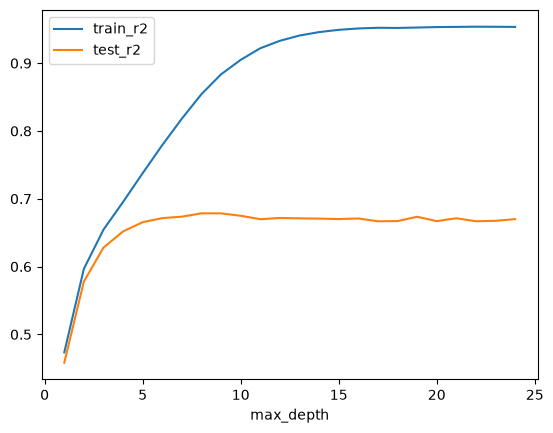

In [63]:
rfg_scores_depths.plot.line('max_depth', ['train_r2', 'test_r2'])

<Axes: xlabel='max_depth'>

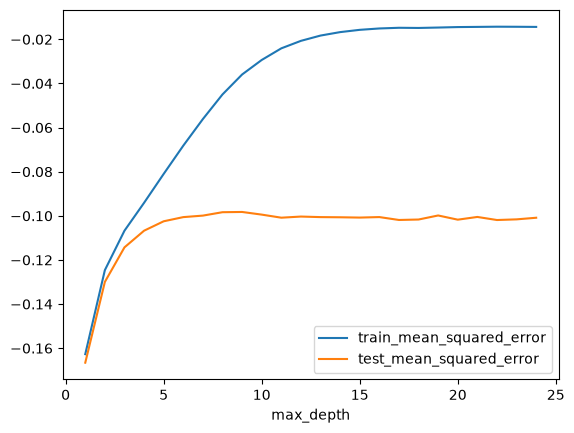

In [64]:
rfg_scores_depths.plot.line('max_depth', ['train_mean_squared_error', 'test_mean_squared_error'])

<Axes: xlabel='max_depth'>

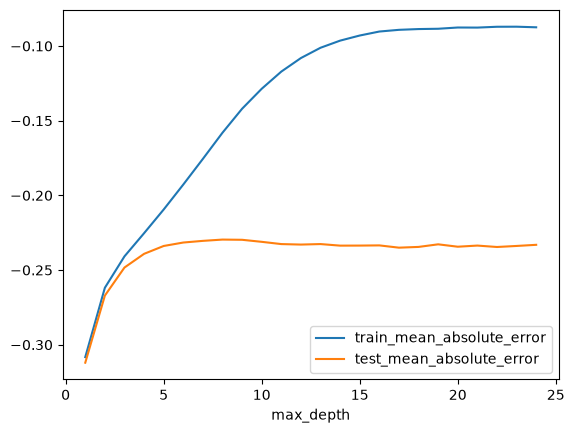

In [65]:
rfg_scores_depths.plot.line('max_depth', ['train_mean_absolute_error', 'test_mean_absolute_error'])

In [66]:
gccv1 = GridSearchCV(RandomForestRegressor(random_state=213), {
    'max_depth': [None, 10, 20, 30],
    'min_samples_leaf': range(1, 5),
    'max_features': [5, 10, 15, 20],
    'n_estimators': [50, 100, 150, 200]
}, cv=cv)
gccv2 = GridSearchCV(RandomForestRegressor(random_state=213), {
    'max_depth': [None, 10, 20, 30],
    'min_samples_leaf': range(1, 5),
    'max_features': [5, 10, 15, 20],
    'n_estimators': [50, 100, 150, 200]
}, cv=cv)

In [67]:
gccv1.fit(X_train, np.ravel(y1_train))
gccv2.fit(X_train, np.ravel(y2_train))

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...dom_state=213)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'max_features': [5, 10, ...], 'min_samples_leaf': range(1, 5), 'n_estimators': [50, 100, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support f

In [68]:
print('Best params for Energy Use:', gccv1.best_params_)
print('Best params for Greenhouse Gas Emission:', gccv2.best_params_)

Best params for Energy Use: {'max_depth': 10, 'max_features': 10, 'min_samples_leaf': 2, 'n_estimators': 200}
Best params for Greenhouse Gas Emission: {'max_depth': 10, 'max_features': 5, 'min_samples_leaf': 1, 'n_estimators': 200}


In [69]:
rfg1 = RandomForestRegressor(random_state=213)
rfg1.fit(X_train, np.ravel(y1_train))

rfg2 = RandomForestRegressor(random_state=213)
rfg2.fit(X_train, np.ravel(y2_train))

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",213
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease 

In [70]:
y1_pred_gccv = gccv1.predict(X_test)
y1_pred_rfg = rfg1.predict(X_test)

print('Random Forest Generator avec GridSearch')
print('r2:', r2_score(y1_test, y1_pred_gccv))
print('mean absolute error:', mean_absolute_error(y1_test, y1_pred_gccv))
print('mean squared error:', mean_squared_error(y1_test, y1_pred_gccv))
print()
print('Random Forest Generator sans GridSearch')
print('r2:', r2_score(y1_test, y1_pred_rfg))
print('mean absolute error:', mean_absolute_error(y1_test, y1_pred_rfg))
print('mean squared error:', mean_squared_error(y1_test, y1_pred_rfg))

Random Forest Generator avec GridSearch
r2: 0.690712680155771
mean absolute error: 0.2262035765300605
mean squared error: 0.09598950507291691

Random Forest Generator sans GridSearch
r2: 0.6833036425918386
mean absolute error: 0.2260370571172706
mean squared error: 0.09828895223158704


In [71]:
y2_pred_gccv = gccv2.predict(X_test)
y2_pred_rfg = rfg2.predict(X_test)

print('Random Forest Generator avec GridSearch')
print('r2:', r2_score(y2_test, y2_pred_gccv))
print('mean absolute error:', mean_absolute_error(y2_test, y2_pred_gccv))
print('mean squared error:', mean_squared_error(y2_test, y2_pred_gccv))
print()
print('Random Forest Generator sans GridSearch')
print('r2:', r2_score(y2_test, y2_pred_rfg))
print('mean absolute error:', mean_absolute_error(y2_test, y2_pred_rfg))
print('mean squared error:', mean_squared_error(y2_test, y2_pred_rfg))

Random Forest Generator avec GridSearch
r2: 0.5047591811211354
mean absolute error: 0.3459759980060624
mean squared error: 0.2067043976943893

Random Forest Generator sans GridSearch
r2: 0.48530038323918834
mean absolute error: 0.34510539839505944
mean squared error: 0.2148261415868865


In [72]:
imp1 = permutation_importance(gccv1, X_test, np.ravel(y1_test))
imp2 = permutation_importance(gccv2, X_test, np.ravel(y2_test))

In [73]:
for i in range(X_test.shape[1]):
    print(f'{X_test.columns[i]}: {imp1.importances_mean[i]}')
print()
for i in range(X_test.shape[1]):
    print(f'{X_test.columns[i]}: {imp2.importances_mean[i]}')

BuildingAge: 0.007422036155661327
NumberofBuildings: 0.0037534774861712307
NumberofFloors: 0.05439364060336198
NumberofUseTypes: -7.9090059269471e-05
PropertyGFATotal: 0.6630568069820459
LargestPropertyUseType_0: 0.02346776081527404
LargestPropertyUseType_1: 0.008536620315884268
LargestPropertyUseType_2: 0.05507787167922371
LargestPropertyUseType_3: 0.03236090969302911
LargestPropertyUseType_4: 0.025210767475811968
LargestPropertyUseType_5: 0.012913391873237279
SecondLargestPropertyUseType_0: -0.00045392527925880444
SecondLargestPropertyUseType_1: 0.000744221289642466
SecondLargestPropertyUseType_2: 0.0005244646359442884
SecondLargestPropertyUseType_3: -0.0006923290652440572
SecondLargestPropertyUseType_4: 0.002518678672432073
SecondLargestPropertyUseType_5: -0.00033670752517516166
ThirdLargestPropertyUseType_0: 0.001676497273793709
ThirdLargestPropertyUseType_1: 0.0001671955281352888
ThirdLargestPropertyUseType_2: 0.0008742254557058349
ThirdLargestPropertyUseType_3: -3.778808229406572

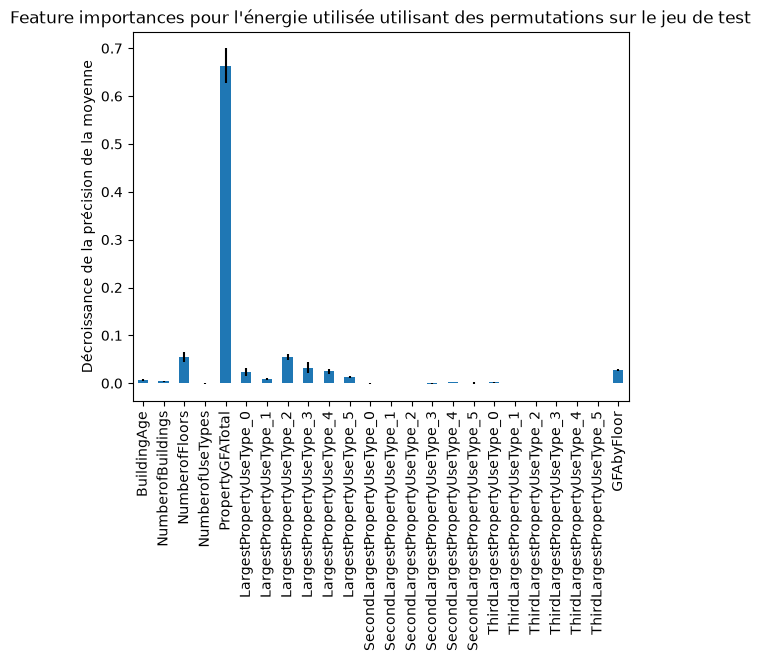

In [74]:
forest_importances = pd.Series(imp1.importances_mean, index=X_test.columns)
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=imp1.importances_std)
ax.set_title("Feature importances pour l'énergie utilisée utilisant des permutations sur le jeu de test")
ax.set_ylabel("Décroissance de la précision de la moyenne")
plt.show()

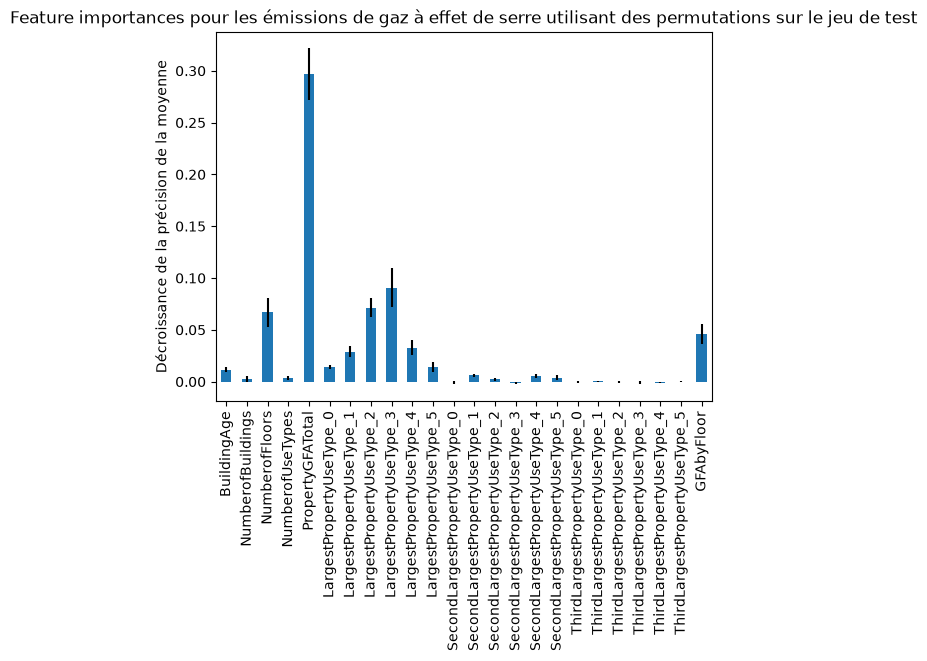

In [75]:
forest_importances = pd.Series(imp2.importances_mean, index=X_test.columns)
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=imp2.importances_std)
ax.set_title("Feature importances pour les émissions de gaz à effet de serre utilisant des permutations sur le jeu de test")
ax.set_ylabel("Décroissance de la précision de la moyenne")
plt.show()

In [76]:
correlation_matrix = building_consumption_encoded[
    ['YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)',
     'LargestPropertyUseTypeGFA', 'SiteEnergyUse(kBtu)_log10', 'TotalGHGEmissions_log10', 'BuildingAge', 'NumberofUseTypes',
     'GFAbyFloor']
].corr(numeric_only=True)

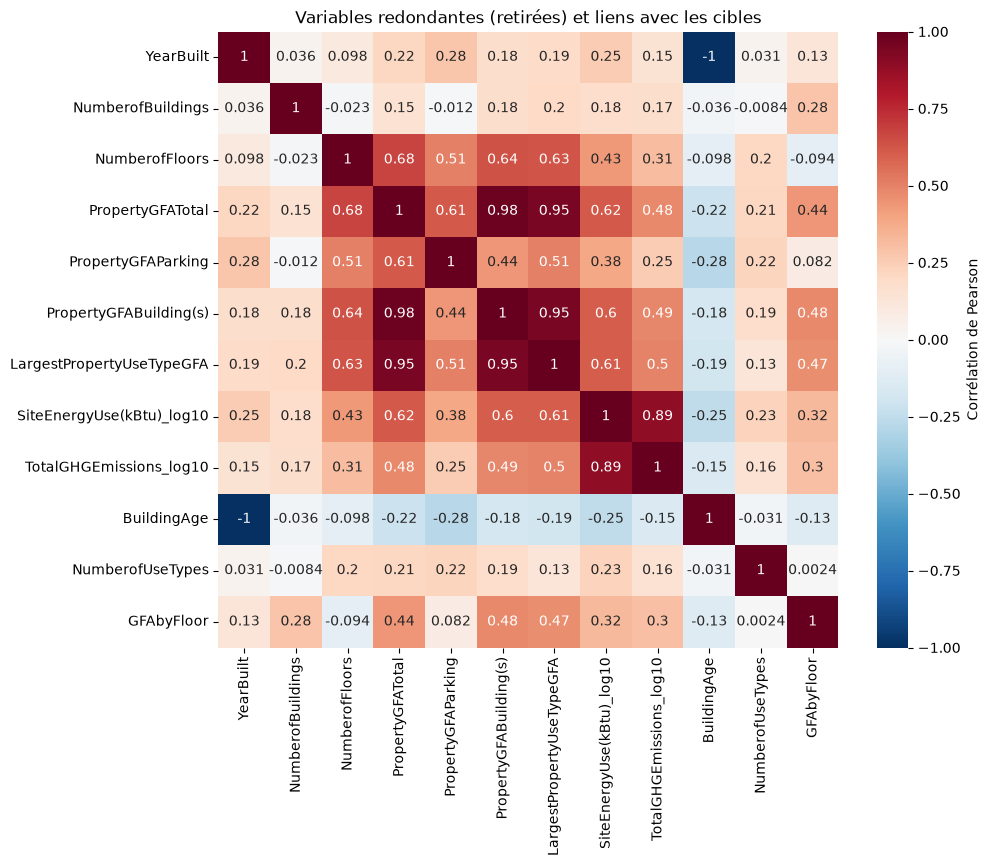

In [77]:
fig, ax = plt.subplots(figsize=(10,8))
sns.heatmap(correlation_matrix, cmap="RdBu_r", annot=True, cbar_kws={'label': 'Corrélation de Pearson'}, ax=ax)
ax.set_title('Variables redondantes (retirées) et liens avec les cibles')
plt.show()

In [85]:
gccv1.best_estimator_

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",213
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

In [89]:
import shap

explainer1 = shap.TreeExplainer(gccv1.best_estimator_)
explainer2 = shap.TreeExplainer(gccv2.best_estimator_)
explanation1 = explainer1(X)
explanation2 = explainer2(X)

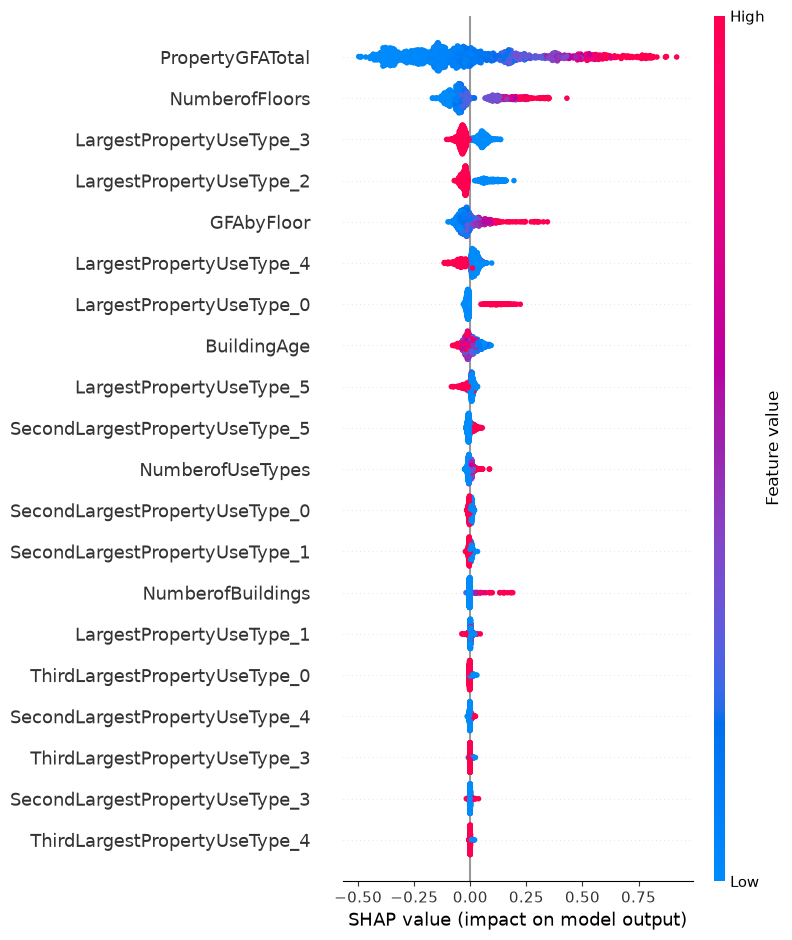

In [136]:
shap.summary_plot(explanation1.values, X)

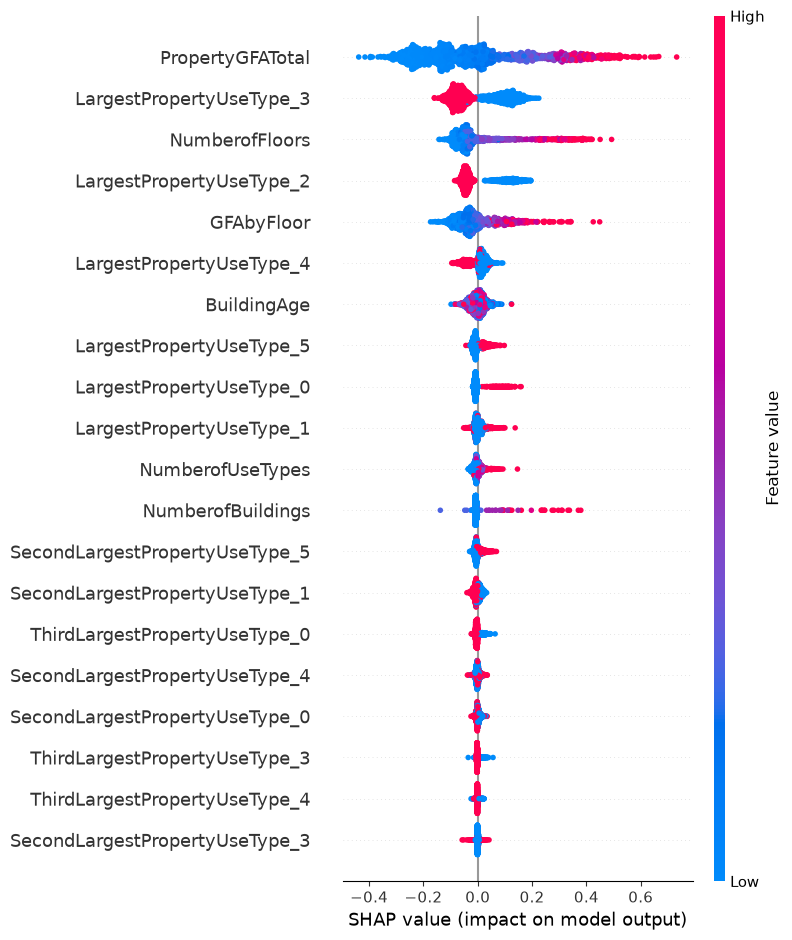

In [165]:
shap.summary_plot(explanation2.values, X)

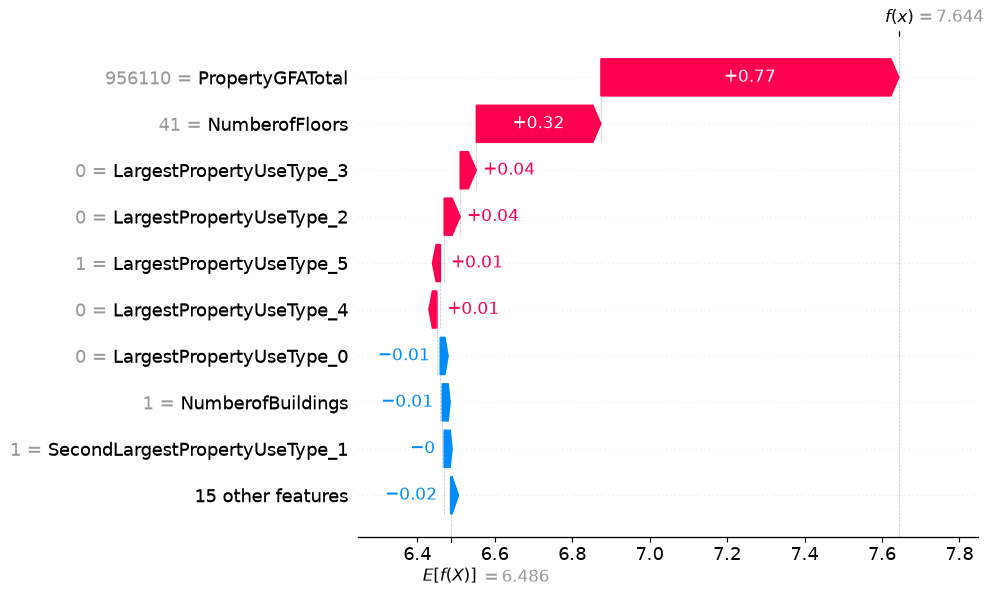

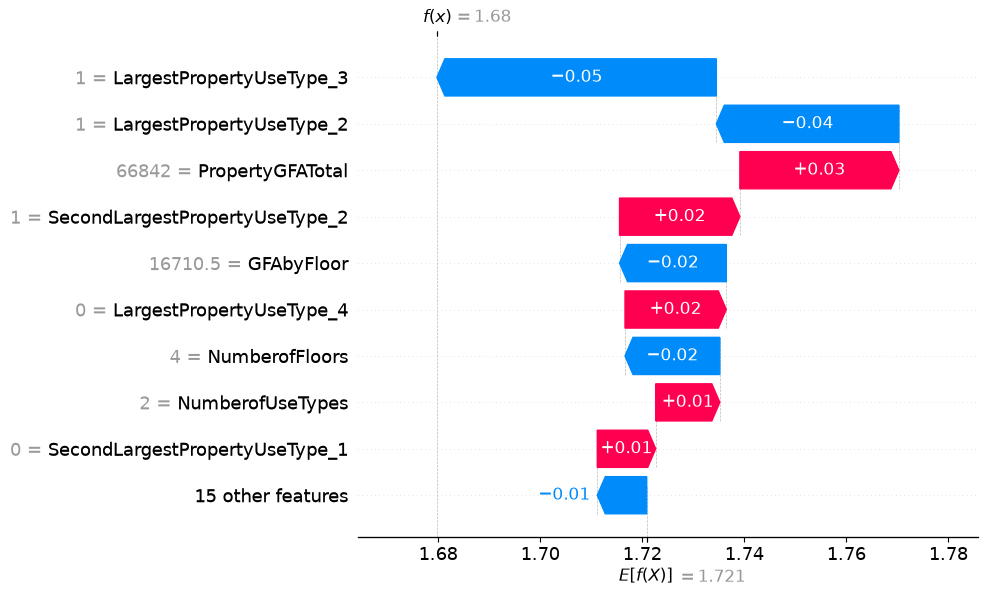

In [163]:
shap.waterfall_plot(explanation1[2])
shap.waterfall_plot(explanation2[435])

/Users/kevin/Documents/OpenClassrooms/Projet3/P3-Anticipez-les-besoin-en-consommations-de-batiments/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/Users/kevin/Documents/OpenClassrooms/Projet3/P3-Anticipez-les-besoin-en-consommations-de-batiments/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


Intercept 6.426969179426099
Prediction_local [7.37192466]
Right: 7.643657491959817
Figure(640x480)
Intercept 2.282101795950174
Prediction_local [1.60342058]
Right: 1.6797457396896576
Figure(640x480)


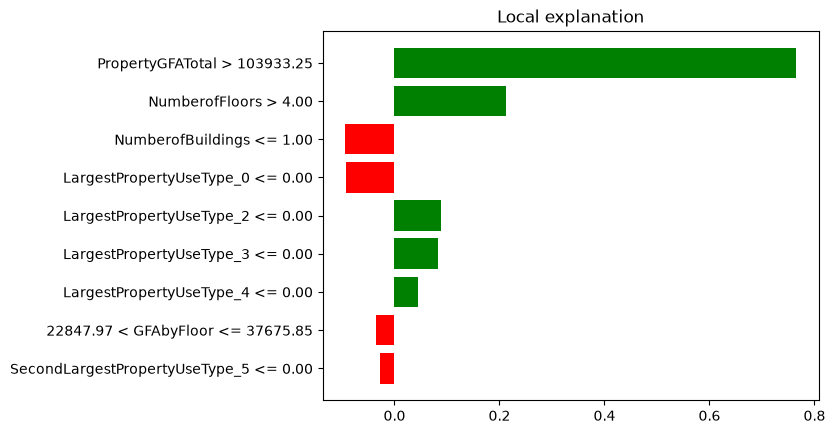

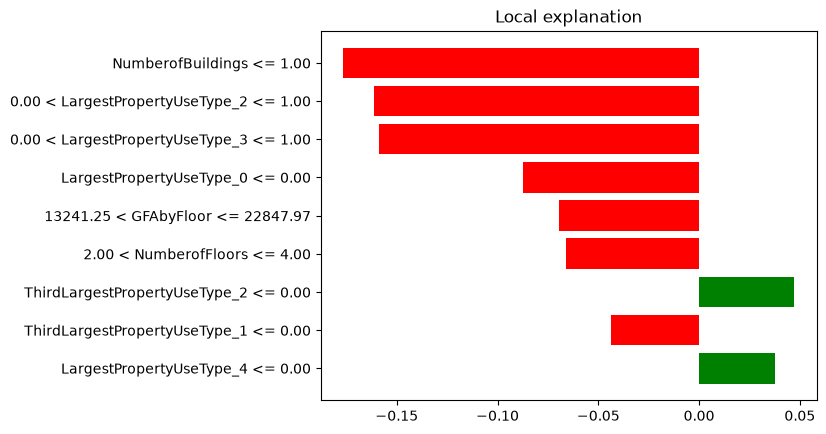

In [164]:
import lime
import lime.lime_tabular

explainer = lime.lime_tabular.LimeTabularExplainer(X.values, feature_names=X.columns.values.tolist(),
                                                  class_names=['MEDV'], verbose=True, mode='regression')
exp = explainer.explain_instance(X.values[2], gccv1.predict, num_features=9)
print(exp.as_pyplot_figure())
exp = explainer.explain_instance(X.values[435], gccv2.predict, num_features=9)
print(exp.as_pyplot_figure())